In [8]:
%pip install -q ultralytics

In [16]:
import os
import json
import random
import shutil
from pathlib import Path

import torch
import ultralytics
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO
from IPython.display import display, Image

print("Libraries imported successfully!")
print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Enable T4 GPU in Runtime settings.")

Libraries imported successfully!
Ultralytics: 8.4.215
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [17]:
from google.colab import drive

drive.mount("/content/gdrive", force_remount=False)

print("Google Drive mounted:",
      os.path.isdir("/content/gdrive/MyDrive"))

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
Google Drive mounted: True


In [18]:
BASE_DIR = Path("/content/gdrive/MyDrive/SkinCare_AI/ACNE04")

DATASET_DIR = BASE_DIR / "yolo_dataset_v1"
DATA_YAML = DATASET_DIR / "data.yaml"

MODEL_OUTPUT_DIR = BASE_DIR / "model_outputs"

MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", BASE_DIR)
print("Dataset directory:", DATASET_DIR)
print("Dataset YAML:", DATA_YAML)
print("Model output directory:", MODEL_OUTPUT_DIR)

assert BASE_DIR.exists(), "ACNE04 directory not found!"
assert DATASET_DIR.exists(), "YOLO dataset directory not found!"
assert DATA_YAML.exists(), "data.yaml not found!"

print("\nDataset paths verified successfully!")

Project directory: /content/gdrive/MyDrive/SkinCare_AI/ACNE04
Dataset directory: /content/gdrive/MyDrive/SkinCare_AI/ACNE04/yolo_dataset_v1
Dataset YAML: /content/gdrive/MyDrive/SkinCare_AI/ACNE04/yolo_dataset_v1/data.yaml
Model output directory: /content/gdrive/MyDrive/SkinCare_AI/ACNE04/model_outputs

Dataset paths verified successfully!


In [19]:
print("YOLO dataset configuration:\n")

with open(DATA_YAML, "r") as file:
    print(file.read())

YOLO dataset configuration:

path: /content/gdrive/MyDrive/SkinCare_AI/ACNE04/yolo_dataset_v1

train: images/train
val: images/validation
test: images/test

nc: 1

names:
  0: acne


In [21]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["train", "validation", "test"]:

    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    labels = list(label_dir.glob("*.txt"))

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))

    assert len(images) == len(labels), (
        f"Image/label count mismatch in {split}"
    )

print("\nDataset verification completed!")


TRAIN
Images: 959
Labels: 959

VALIDATION
Images: 206
Labels: 206

TEST
Images: 292
Labels: 292

Dataset verification completed!


In [22]:
MODEL_NAME = "yolo11n.pt"

EPOCHS = 30
IMAGE_SIZE = 640
BATCH_SIZE = 16
WORKERS = 2
PATIENCE = 10

RUN_NAME = "yolo11n_acne_baseline_retrained"

print("Training configuration:")
print("Model:", MODEL_NAME)
print("Epochs:", EPOCHS)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Run name:", RUN_NAME)
print("Save location:", MODEL_OUTPUT_DIR)

Training configuration:
Model: yolo11n.pt
Epochs: 30
Image size: 640
Batch size: 16
Run name: yolo11n_acne_baseline_retrained
Save location: /content/gdrive/MyDrive/SkinCare_AI/ACNE04/model_outputs


In [ ]:
model = YOLO(MODEL_NAME)

results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=0,
    workers=WORKERS,
    patience=PATIENCE,

    project=str(MODEL_OUTPUT_DIR),
    name=RUN_NAME,

    plots=True,
    save=True,
    save_period=5,

    exist_ok=False
)

print("\nTraining completed!")

print("Training results:", results.save_dir)
print("Best model:",
      Path(results.save_dir) / "weights" / "best.pt")
print("Last model:",
      Path(results.save_dir) / "weights" / "last.pt")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/gdrive/MyDrive/SkinCare_AI/ACNE04/yolo_dataset_v1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_acne_baseli

In [23]:
RUN_DIR = MODEL_OUTPUT_DIR / RUN_NAME

BEST_MODEL_PATH = RUN_DIR / "weights" / "best.pt"
LAST_MODEL_PATH = RUN_DIR / "weights" / "last.pt"

for path in [BEST_MODEL_PATH, LAST_MODEL_PATH]:

    if path.exists():
        size_mb = path.stat().st_size / (1024 * 1024)

        print("\nFound:", path)
        print("Size:", round(size_mb, 2), "MB")
    else:
        print("\nMissing:", path)

assert BEST_MODEL_PATH.exists(), "Best model checkpoint not found!"

print("\nBest model checkpoint verified!")


Found: /content/gdrive/MyDrive/SkinCare_AI/ACNE04/model_outputs/yolo11n_acne_baseline_retrained/weights/best.pt
Size: 5.24 MB

Found: /content/gdrive/MyDrive/SkinCare_AI/ACNE04/model_outputs/yolo11n_acne_baseline_retrained/weights/last.pt
Size: 5.24 MB

Best model checkpoint verified!


In [24]:
best_model = YOLO(str(BEST_MODEL_PATH))

print("Best YOLO11n model loaded successfully!")

Best YOLO11n model loaded successfully!


In [25]:
validation_results = best_model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=0,
    plots=True,
    project=str(MODEL_OUTPUT_DIR),
    name="validation_evaluation",
    exist_ok=True
)

print("\nValidation evaluation completed!")
print("Precision:", validation_results.box.mp)
print("Recall:", validation_results.box.mr)
print("mAP50:", validation_results.box.map50)
print("mAP50-95:", validation_results.box.map)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 141.0±193.2 MB/s, size: 881.3 KB)
val: Scanning /content/gdrive/MyDrive/SkinCare_AI/ACNE04/yolo_dataset_v1/labels/validation.cache... 206 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 206/206 33.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 1.1s/it 14.5s
                   all        206       2618      0.389      0.414       0.32     0.0804
Speed: 1.9ms preprocess, 4.9ms inference, 0.0ms loss, 3.1ms postprocess per image
Results saved to /content/gdrive/MyDrive/SkinCare_AI/ACNE04/model_outputs/validation_evaluation

Validation evaluation completed!
Precision: 0.3891681094354376
Recall: 0.4140565317035905
mAP50: 0.32008321305329174
mAP50-95: 0.08036870212594058



image 1/1 /content/gdrive/MyDrive/SkinCare_AI/ACNE04/yolo_dataset_v1/images/validation/levle0_164.jpg: 640x576 3 acnes, 8.2ms
Speed: 3.0ms preprocess, 8.2ms inference, 2.4ms postprocess per image at shape (1, 3, 640, 576)
Results saved to /content/gdrive/MyDrive/SkinCare_AI/ACNE04/model_outputs/validation_prediction_review
Original image: /content/gdrive/MyDrive/SkinCare_AI/ACNE04/yolo_dataset_v1/images/validation/levle0_164.jpg
Predicted image:


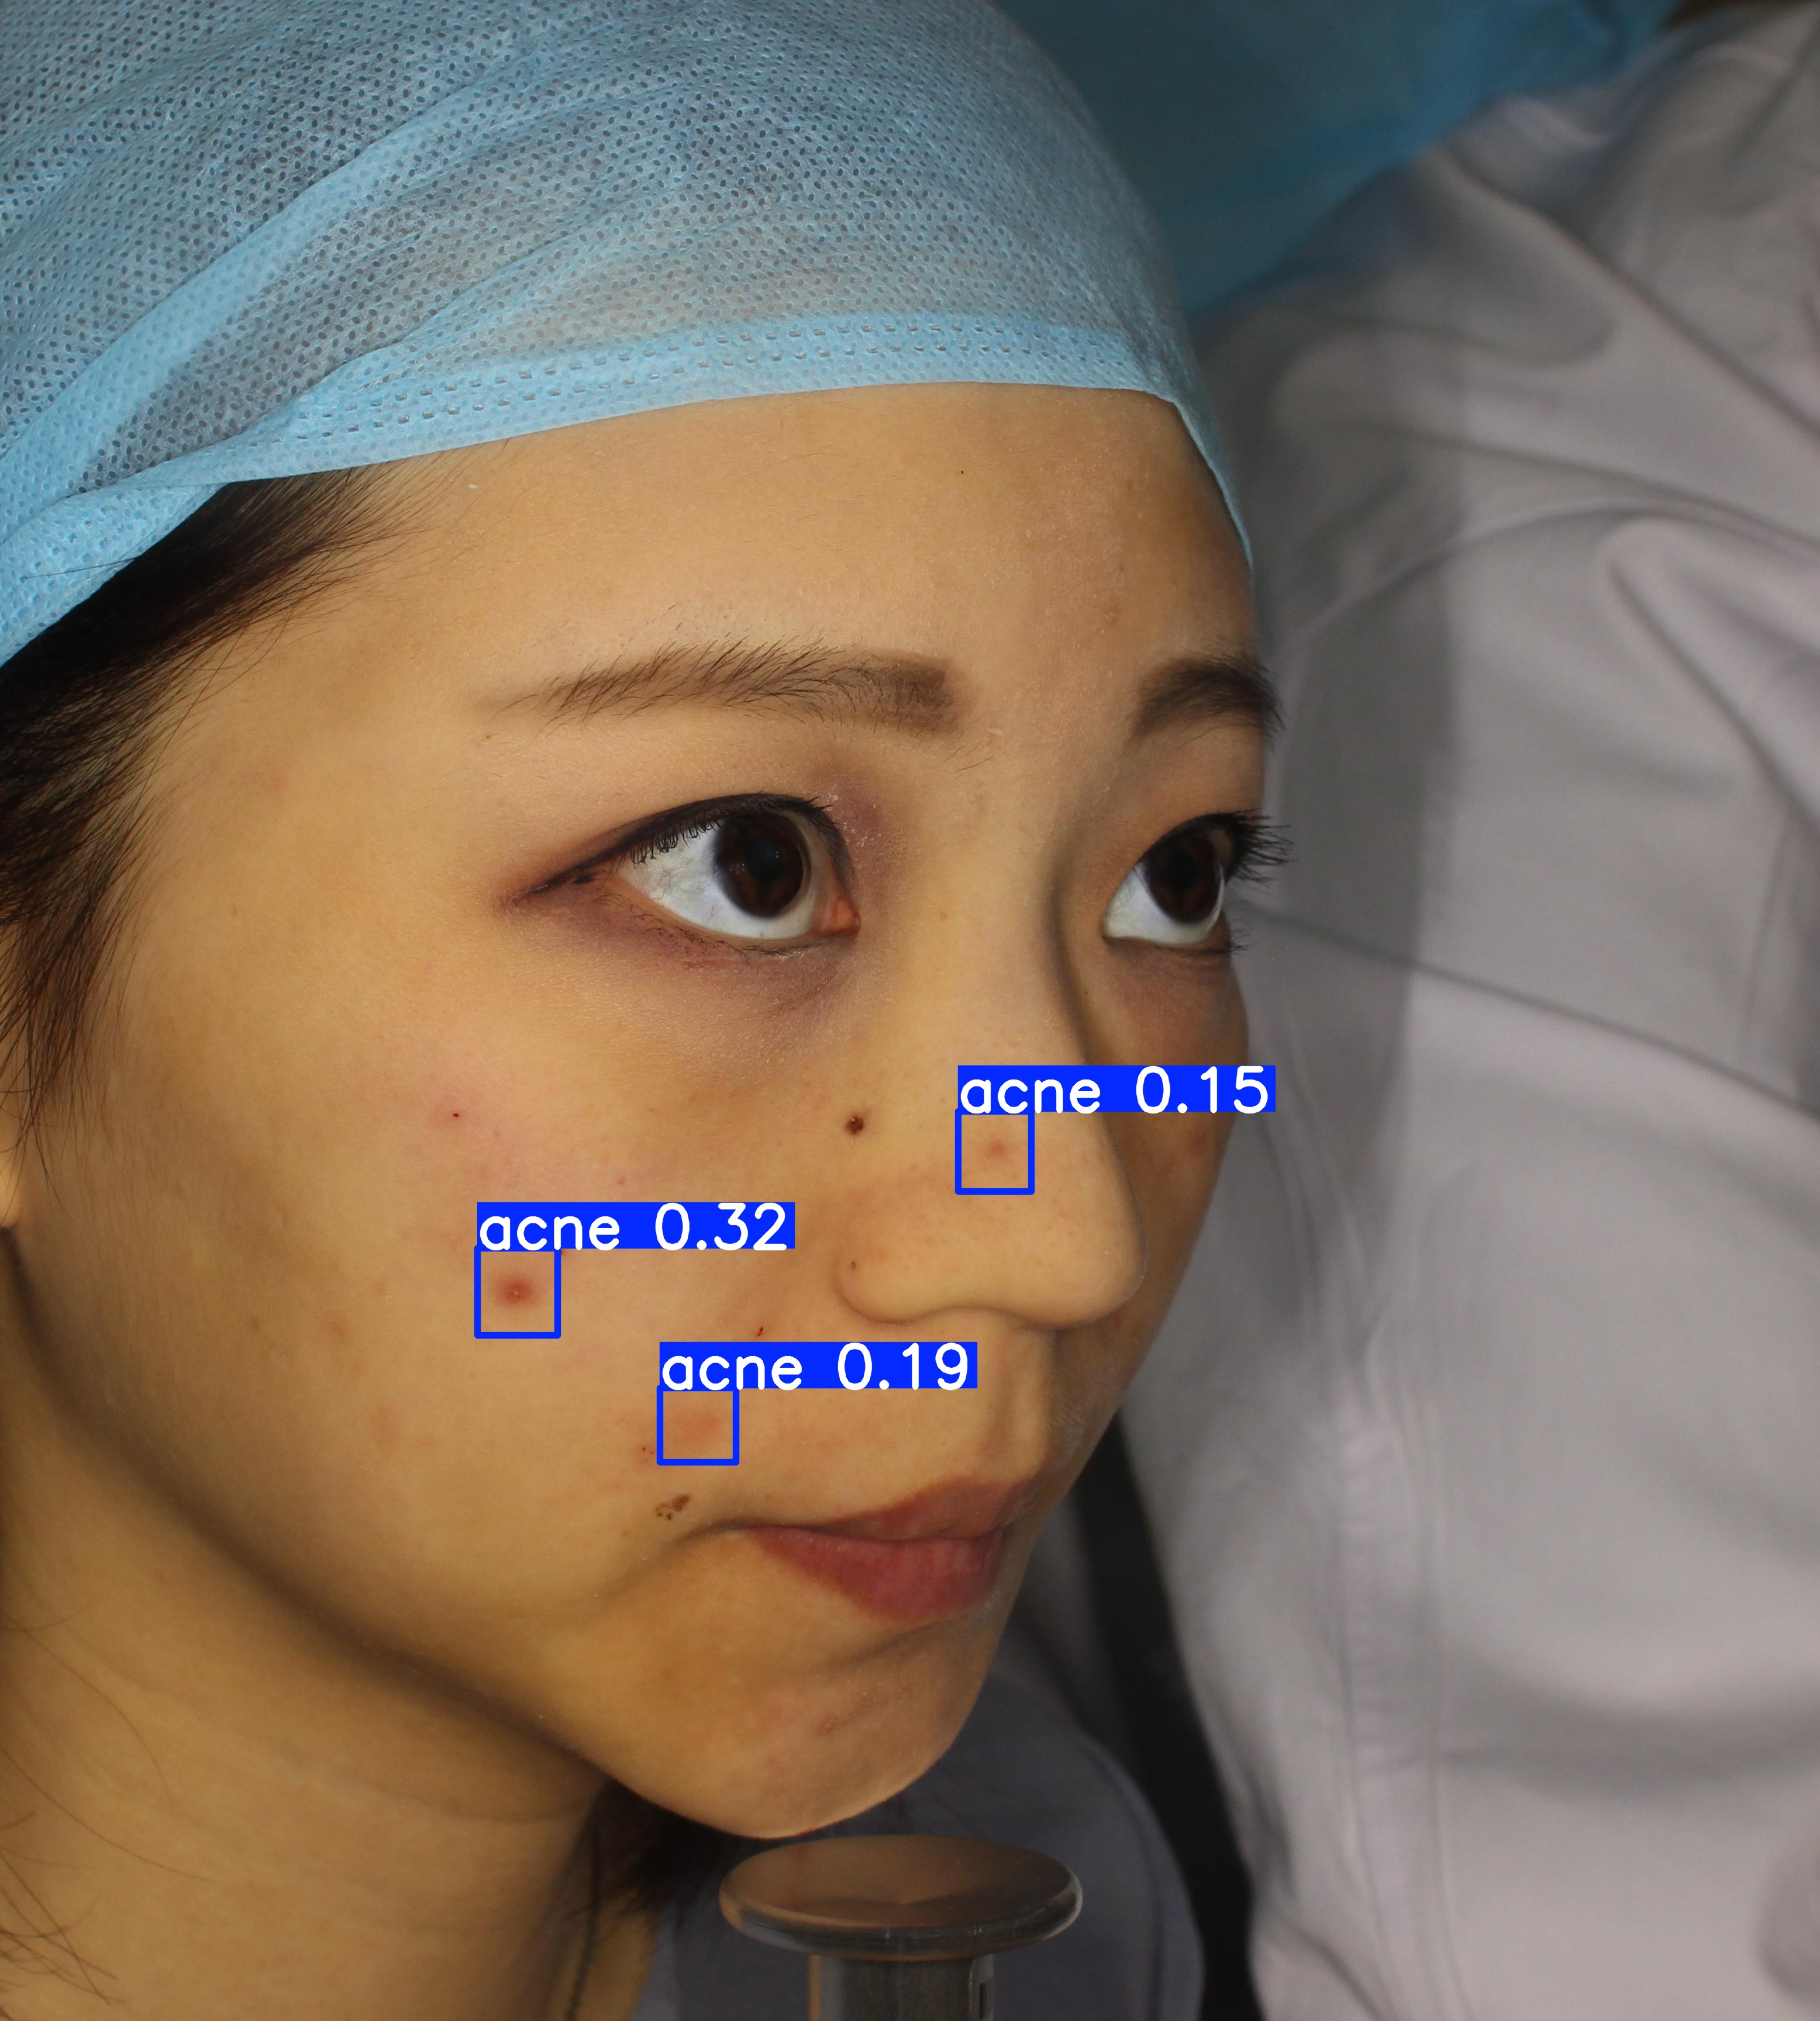

In [26]:
validation_dir = DATASET_DIR / "images" / "validation"

validation_images = [
    p for p in validation_dir.iterdir()
    if p.suffix.lower() in IMAGE_EXTENSIONS
]

assert validation_images, "No validation images found!"

image_path = random.choice(validation_images)

predictions = best_model.predict(
    source=str(image_path),
    conf=0.15,
    imgsz=IMAGE_SIZE,
    save=True,
    project=str(MODEL_OUTPUT_DIR),
    name="validation_prediction_review",
    exist_ok=True
)

saved_image = (
    Path(predictions[0].save_dir) / image_path.name
)

print("Original image:", image_path)
print("Predicted image:")

display(Image(filename=str(saved_image)))

In [27]:
test_results = best_model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=0,
    plots=True,
    project=str(MODEL_OUTPUT_DIR),
    name="final_test_evaluation",
    exist_ok=True
)

print("\nIndependent test evaluation completed!")

print("Precision:", test_results.box.mp)
print("Recall:", test_results.box.mr)
print("mAP50:", test_results.box.map50)
print("mAP50-95:", test_results.box.map)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.3 ms, read: 52.2±113.7 MB/s, size: 837.4 KB)
val: Scanning /content/gdrive/MyDrive/SkinCare_AI/ACNE04/yolo_dataset_v1/labels/test.cache... 292 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 292/292 45.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 1.0it/s 18.1s
                   all        292       3756      0.371      0.416      0.309     0.0802
Speed: 1.6ms preprocess, 4.7ms inference, 0.0ms loss, 2.7ms postprocess per image
Results saved to /content/gdrive/MyDrive/SkinCare_AI/ACNE04/model_outputs/final_test_evaluation

Independent test evaluation completed!
Precision: 0.37055506389705906
Recall: 0.4164004259850905
mAP50: 0.308900337458508
mAP50-95: 0.08015621874750953



results.png


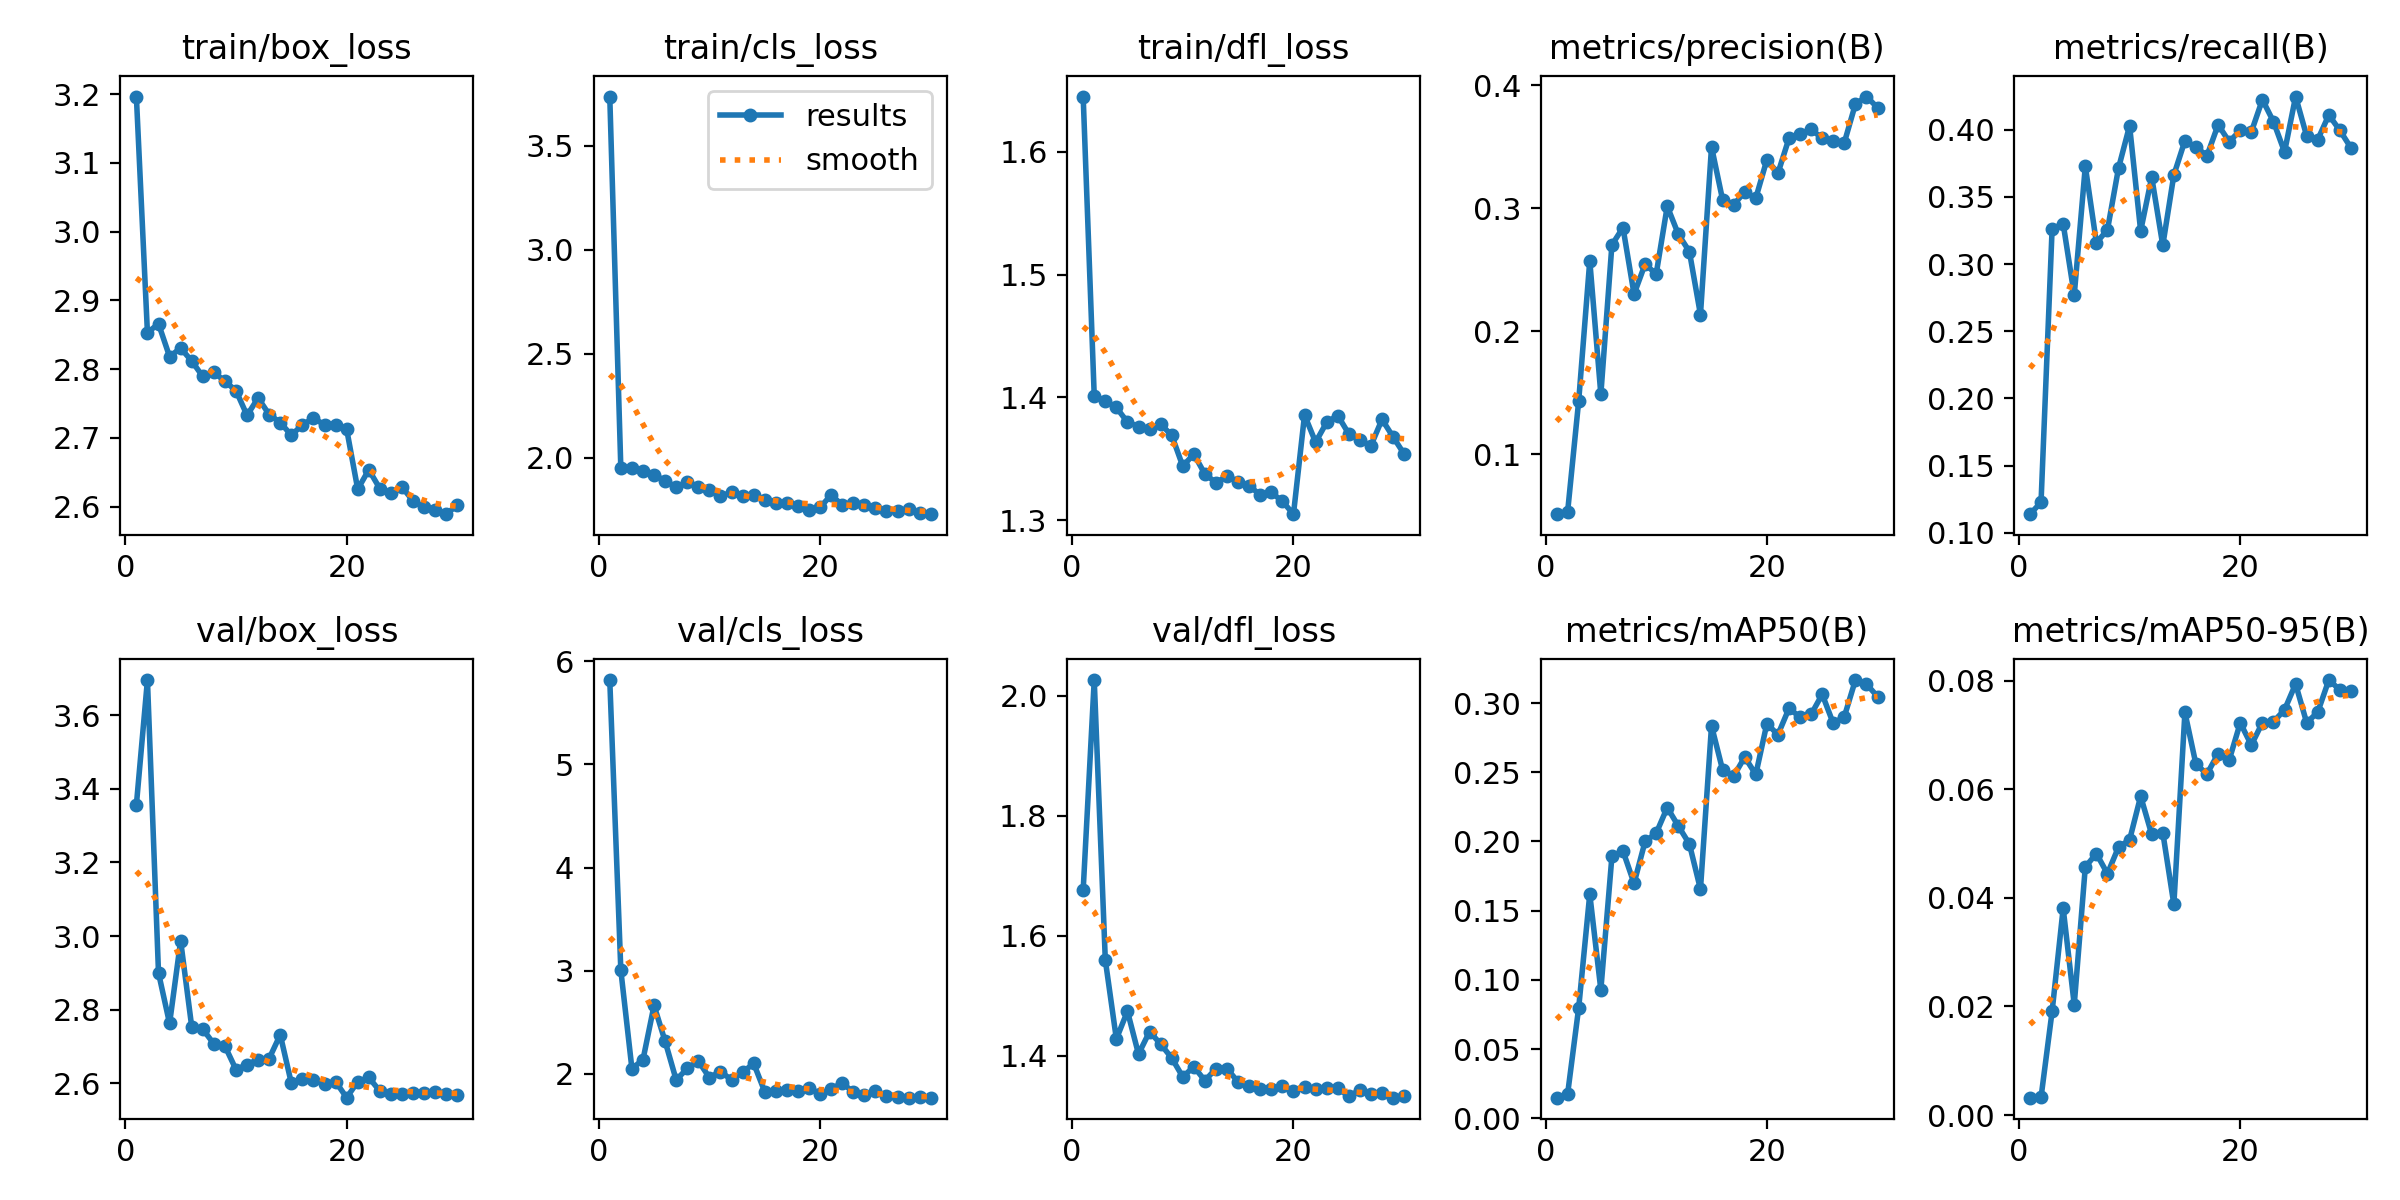


confusion_matrix.png


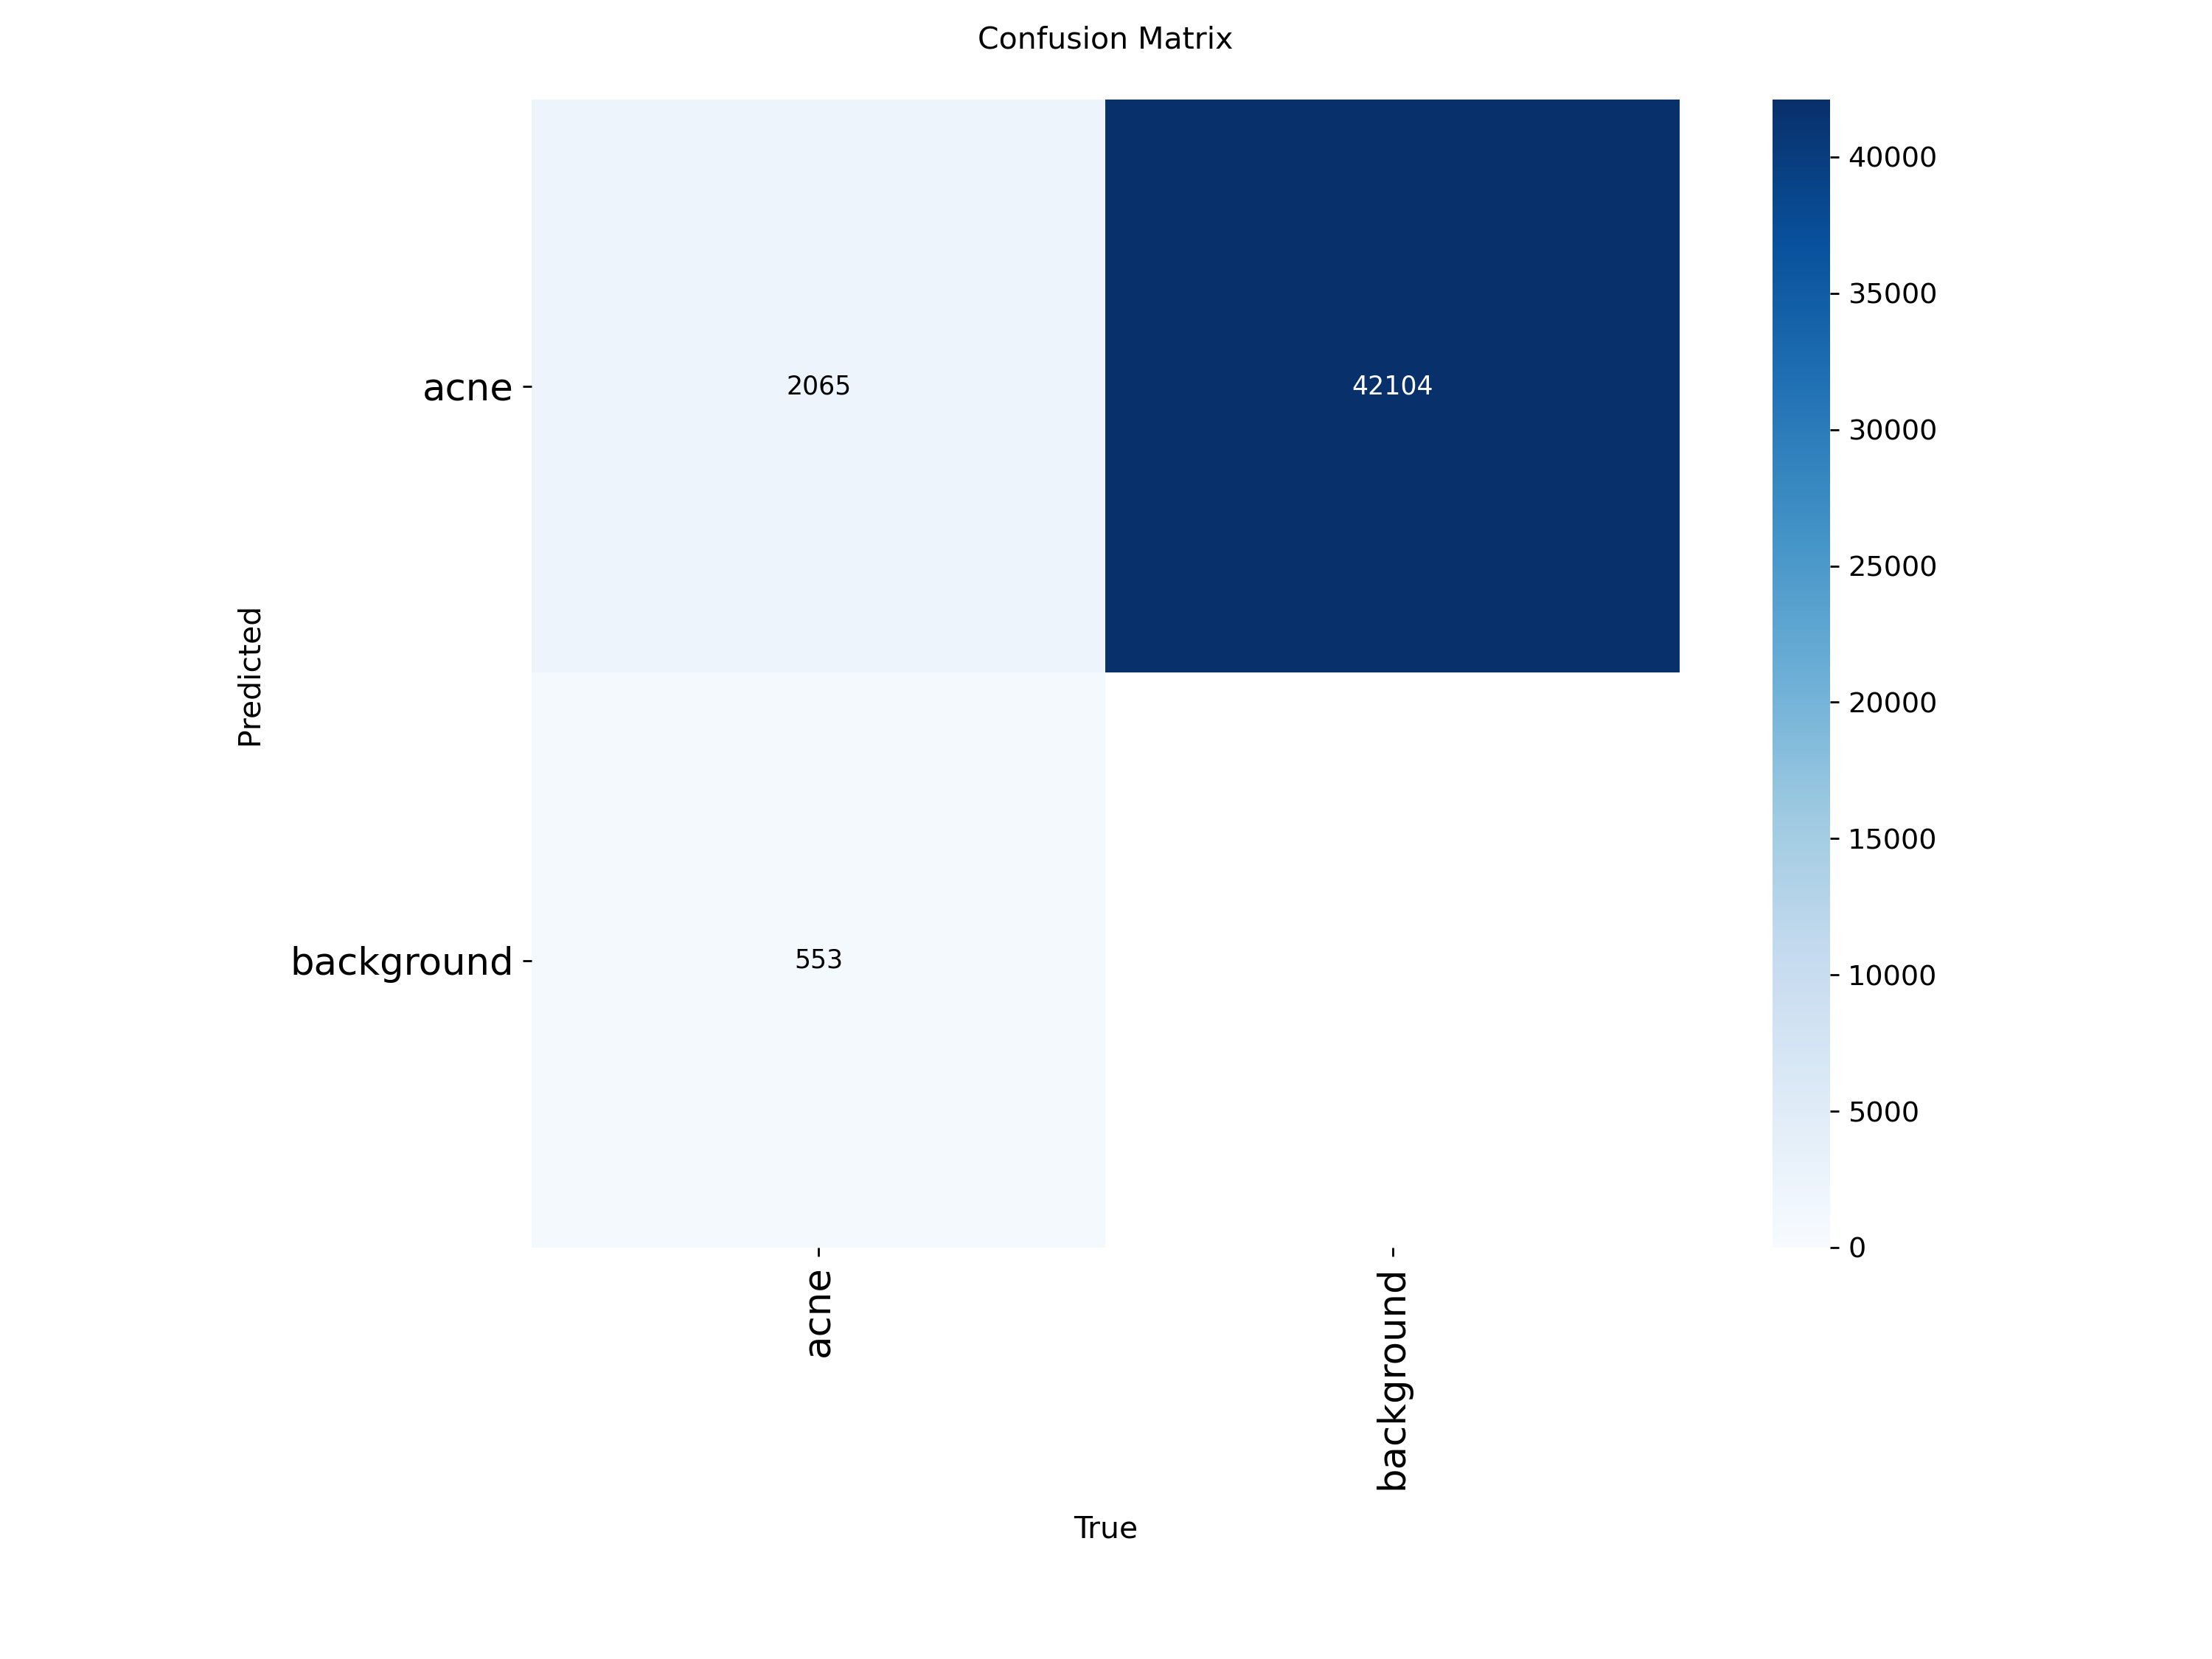

Not found: /content/gdrive/MyDrive/SkinCare_AI/ACNE04/model_outputs/validation_evaluation/PR_curve.png
Not found: /content/gdrive/MyDrive/SkinCare_AI/ACNE04/model_outputs/validation_evaluation/F1_curve.png
Not found: /content/gdrive/MyDrive/SkinCare_AI/ACNE04/model_outputs/validation_evaluation/P_curve.png
Not found: /content/gdrive/MyDrive/SkinCare_AI/ACNE04/model_outputs/validation_evaluation/R_curve.png


In [28]:
from pathlib import Path
from IPython.display import display, Image

RUN_DIR = MODEL_OUTPUT_DIR / RUN_NAME

plot_files = [
    RUN_DIR / "results.png",
    MODEL_OUTPUT_DIR / "validation_evaluation" / "confusion_matrix.png",
    MODEL_OUTPUT_DIR / "validation_evaluation" / "PR_curve.png",
    MODEL_OUTPUT_DIR / "validation_evaluation" / "F1_curve.png",
    MODEL_OUTPUT_DIR / "validation_evaluation" / "P_curve.png",
    MODEL_OUTPUT_DIR / "validation_evaluation" / "R_curve.png"
]

for file_path in plot_files:
    if file_path.exists():
        print(f"\n{file_path.name}")
        display(Image(filename=str(file_path)))
    else:
        print(f"Not found: {file_path}")

In [29]:
import os

folders = [
    MODEL_OUTPUT_DIR / RUN_NAME,
    MODEL_OUTPUT_DIR / "validation_evaluation"
]

for folder in folders:
    print(f"\nFiles in: {folder}")

    if folder.exists():
        for root, dirs, files in os.walk(folder):
            for file in files:
                print(os.path.relpath(os.path.join(root, file), folder))
    else:
        print("Folder not found")


Files in: /content/gdrive/MyDrive/SkinCare_AI/ACNE04/model_outputs/yolo11n_acne_baseline_retrained
args.yaml
labels.jpg
train_batch0.jpg
train_batch1.jpg
train_batch2.jpg
train_batch1200.jpg
train_batch1201.jpg
train_batch1202.jpg
results.csv
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_pred.jpg
val_batch1_labels.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg
BoxPR_curve.png
BoxF1_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix_normalized.png
confusion_matrix.png
results.png
weights/epoch0.pt
weights/epoch5.pt
weights/epoch10.pt
weights/epoch15.pt
weights/epoch20.pt
weights/epoch25.pt
weights/last.pt
weights/best.pt

Files in: /content/gdrive/MyDrive/SkinCare_AI/ACNE04/model_outputs/validation_evaluation
val_batch0_pred.jpg
val_batch0_labels.jpg
val_batch1_pred.jpg
val_batch1_labels.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg
BoxPR_curve.png
BoxF1_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix_normalized.png
confusion_matrix.png


BoxPR_curve.png


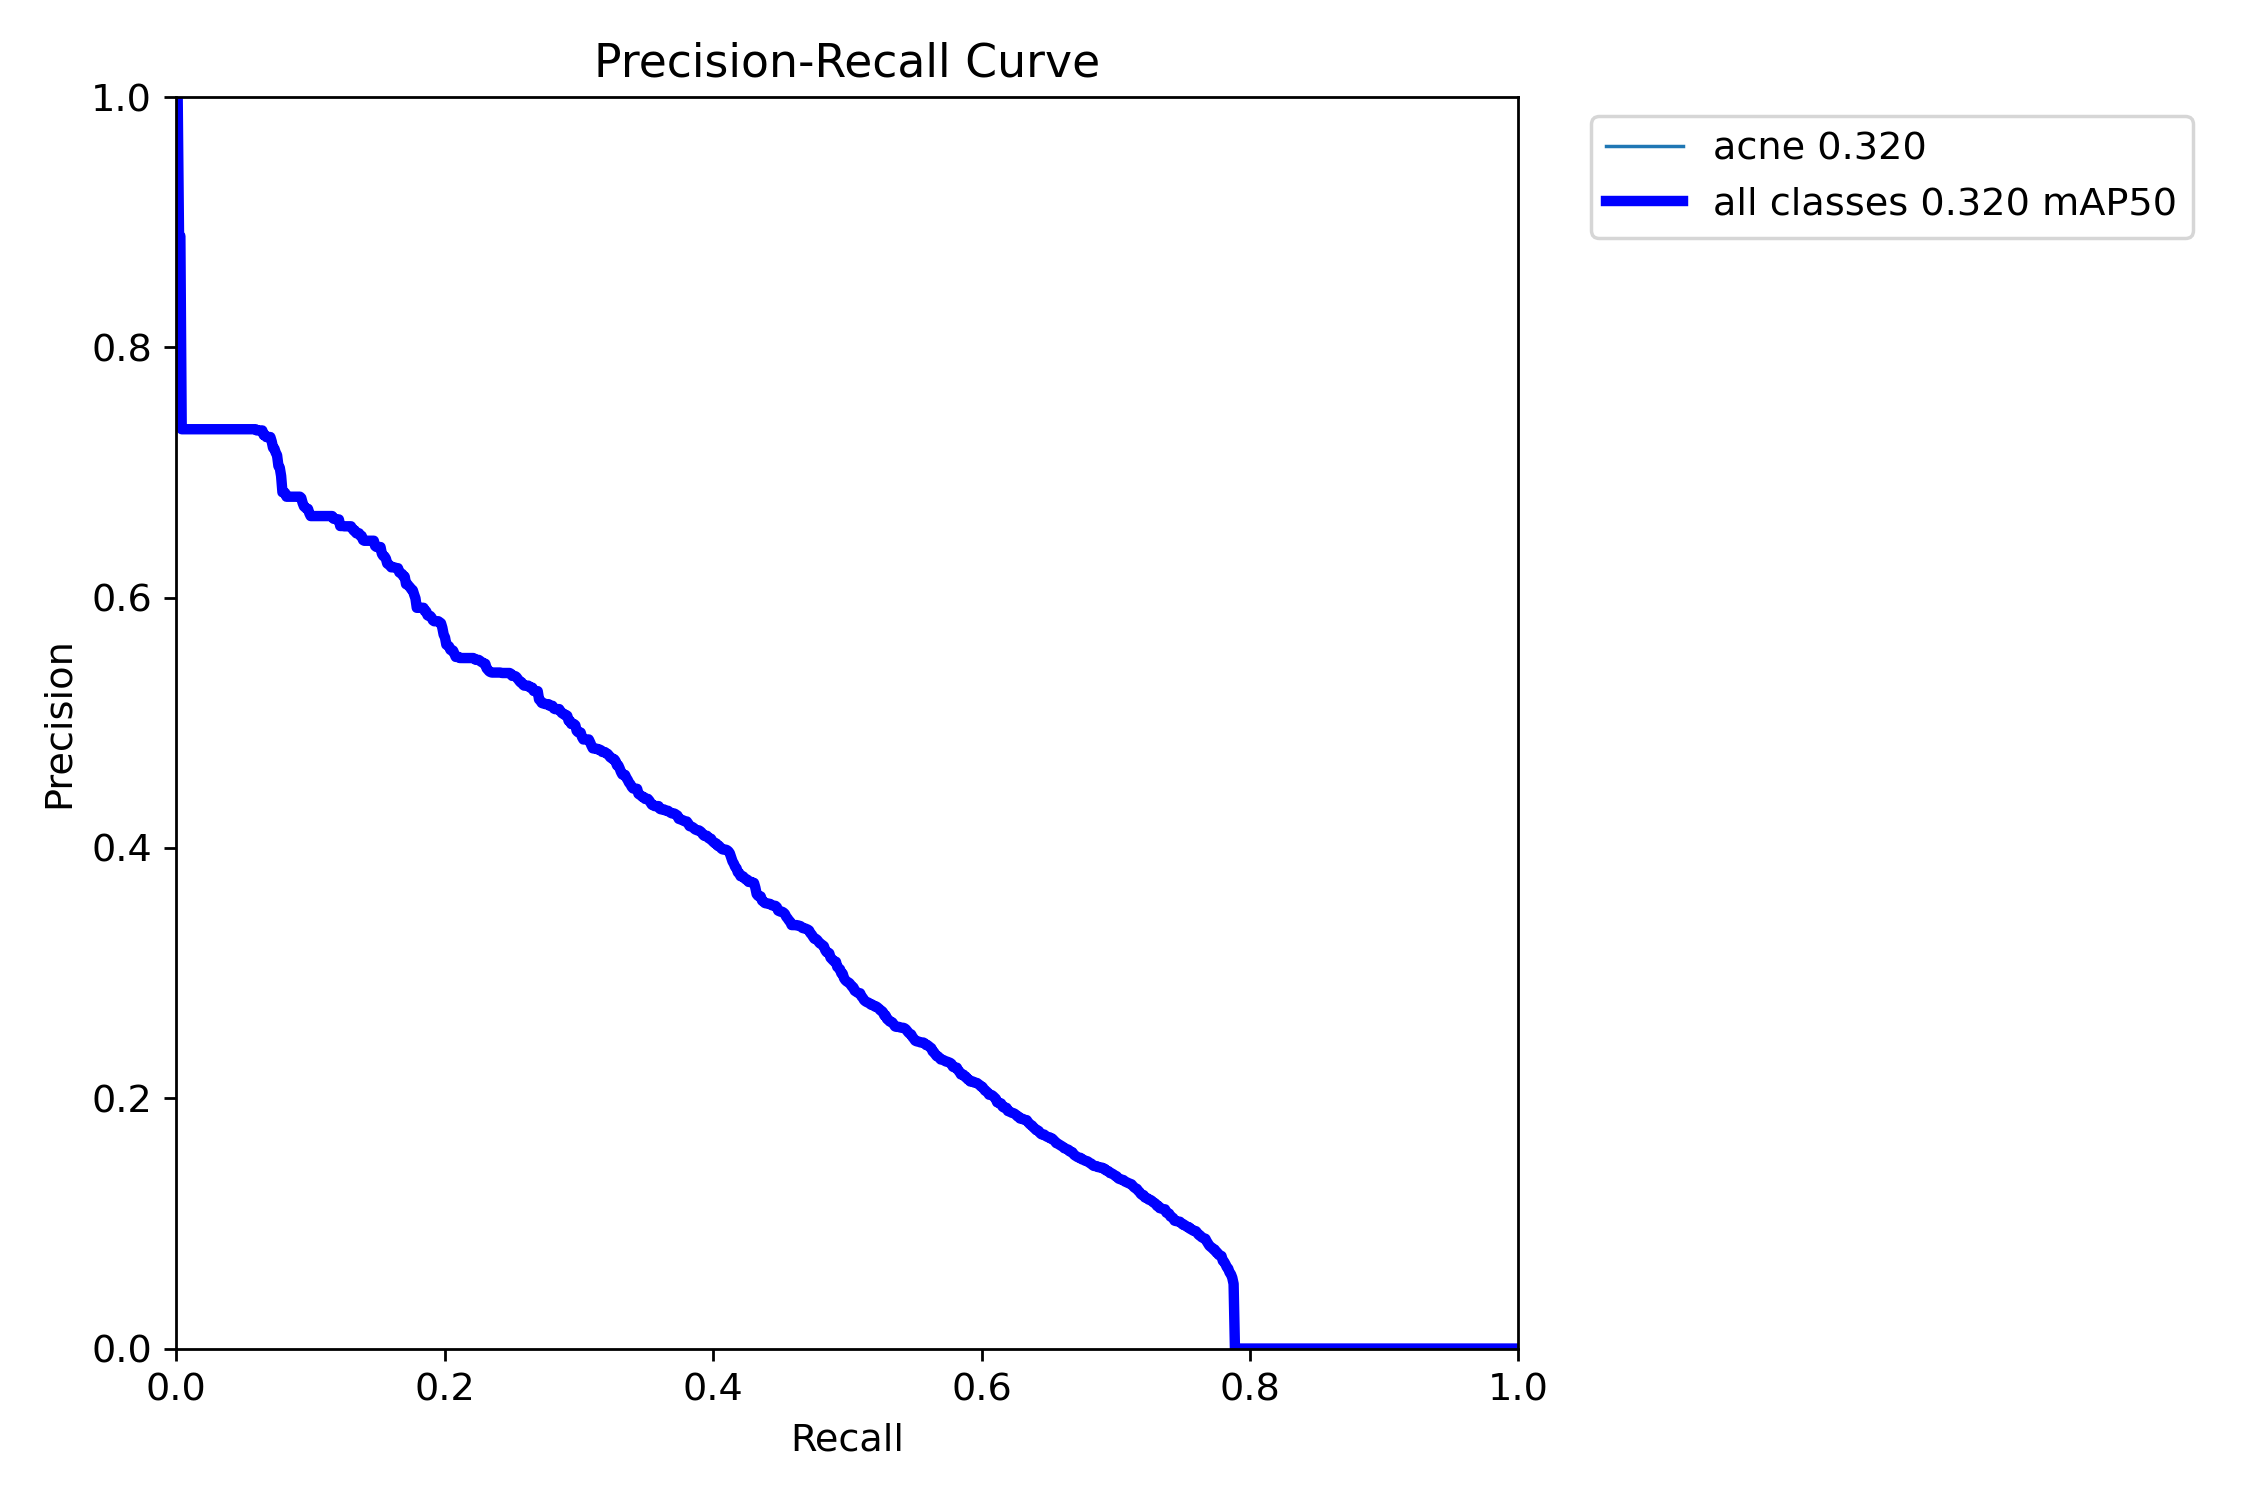

BoxF1_curve.png


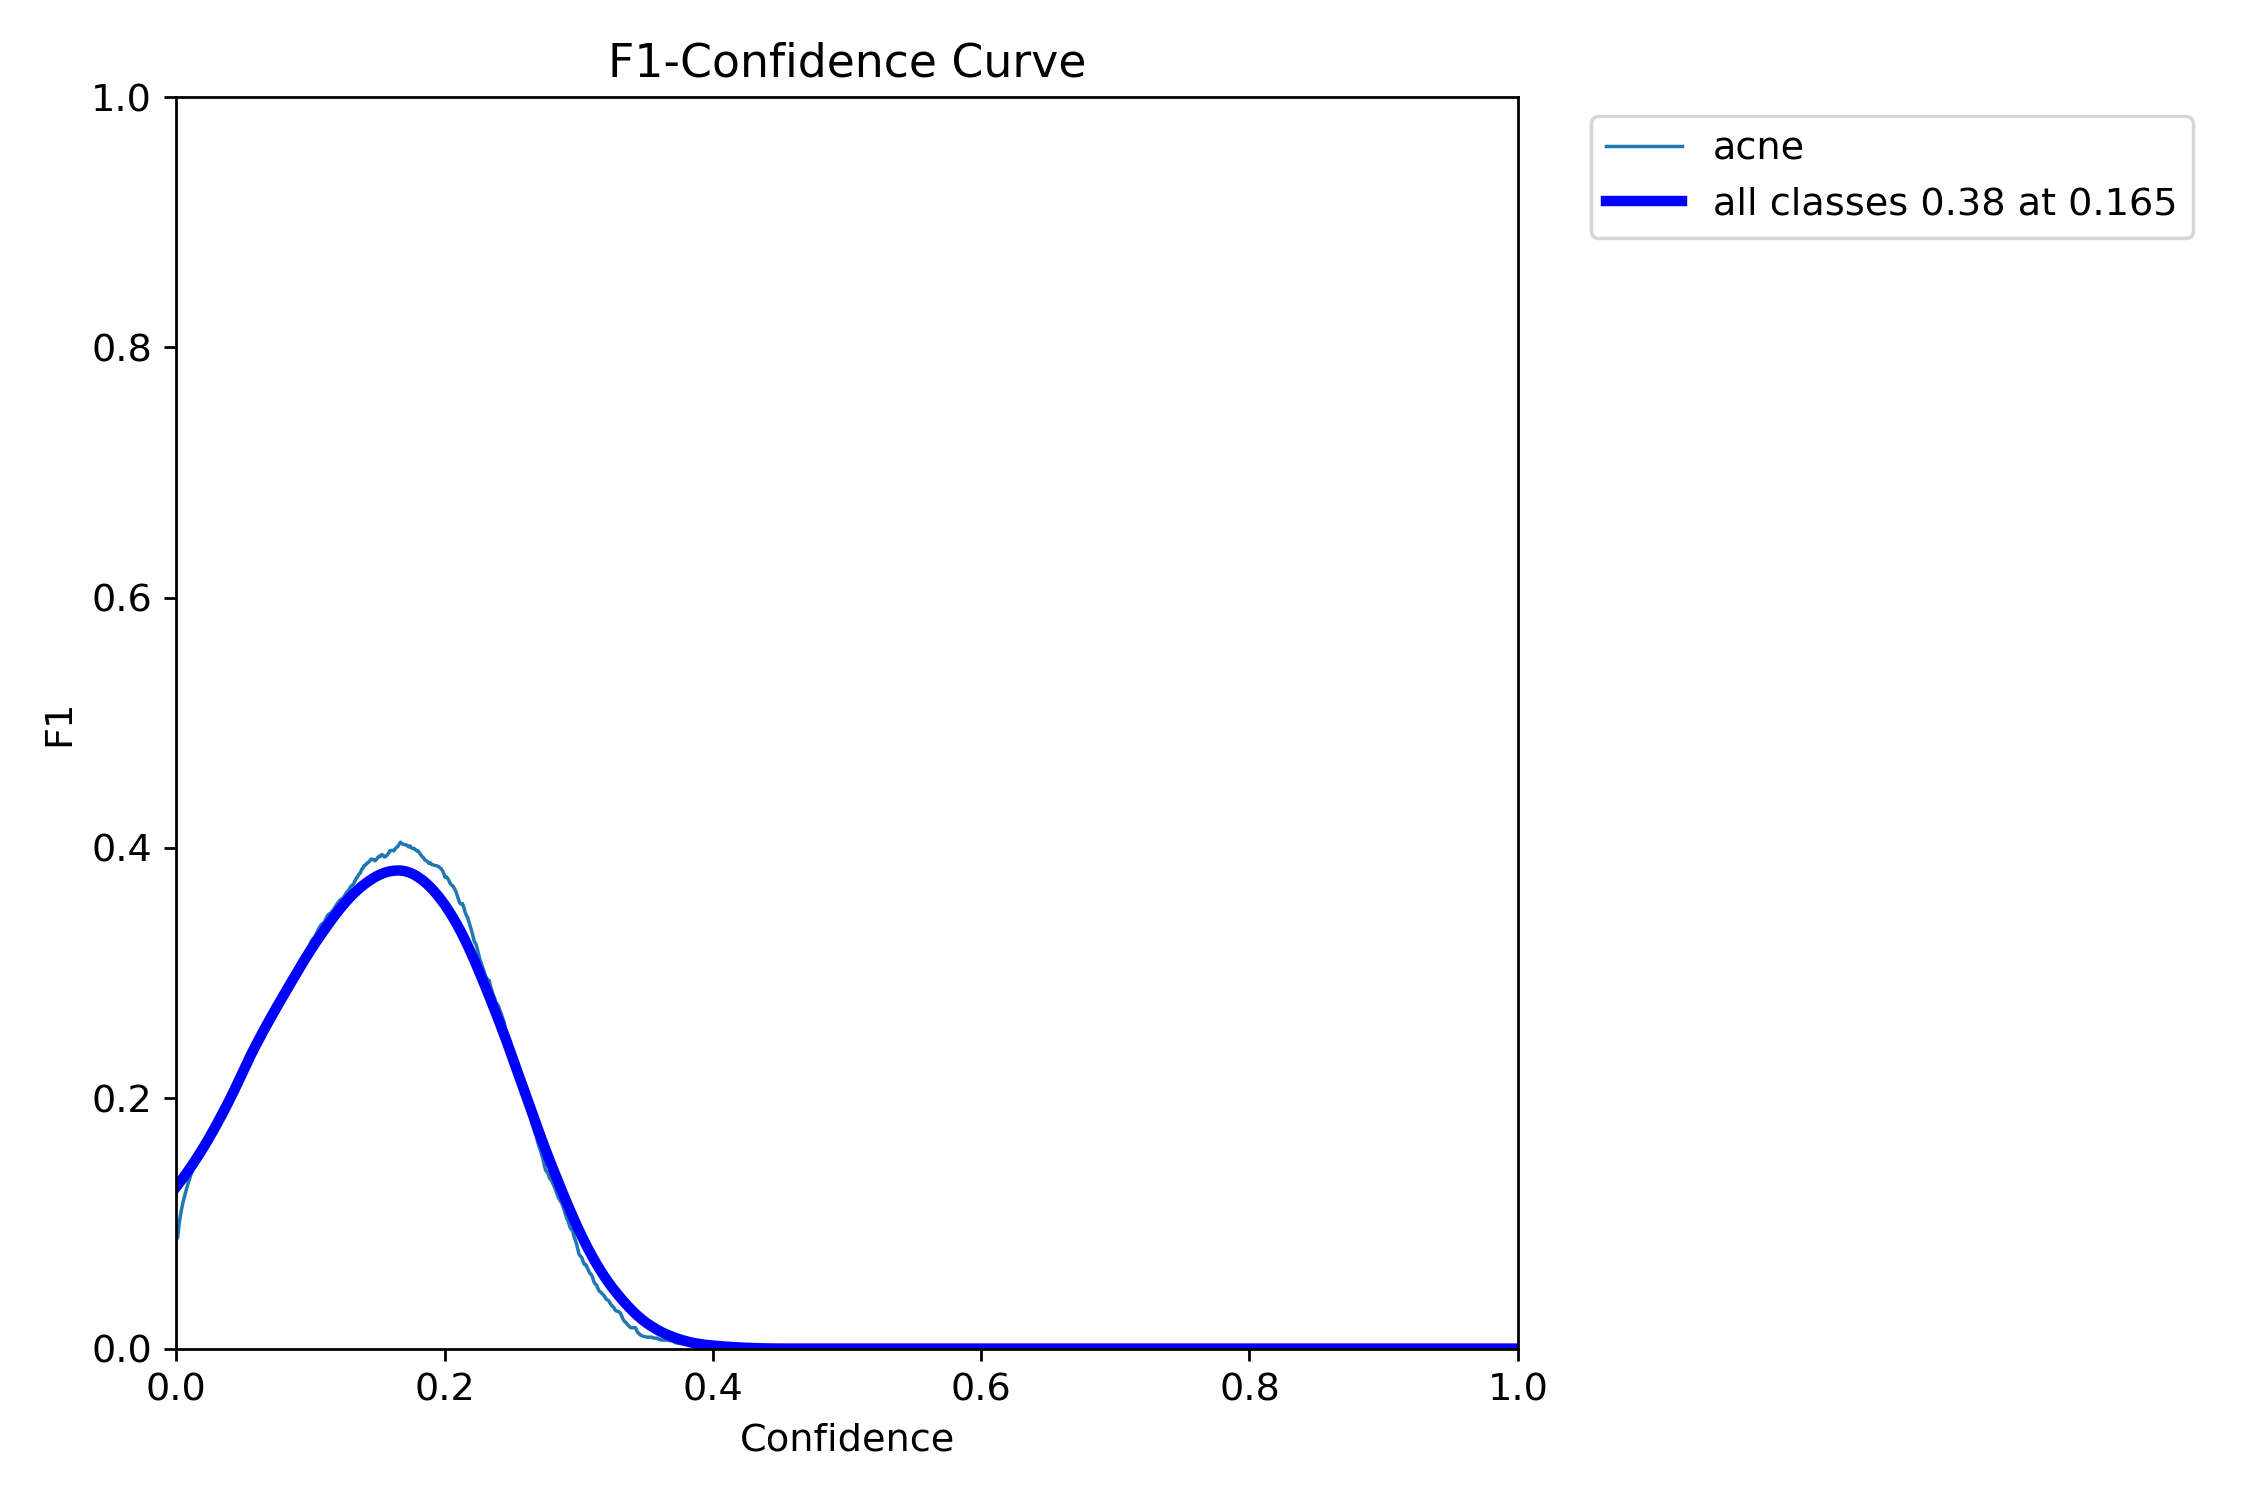

BoxP_curve.png


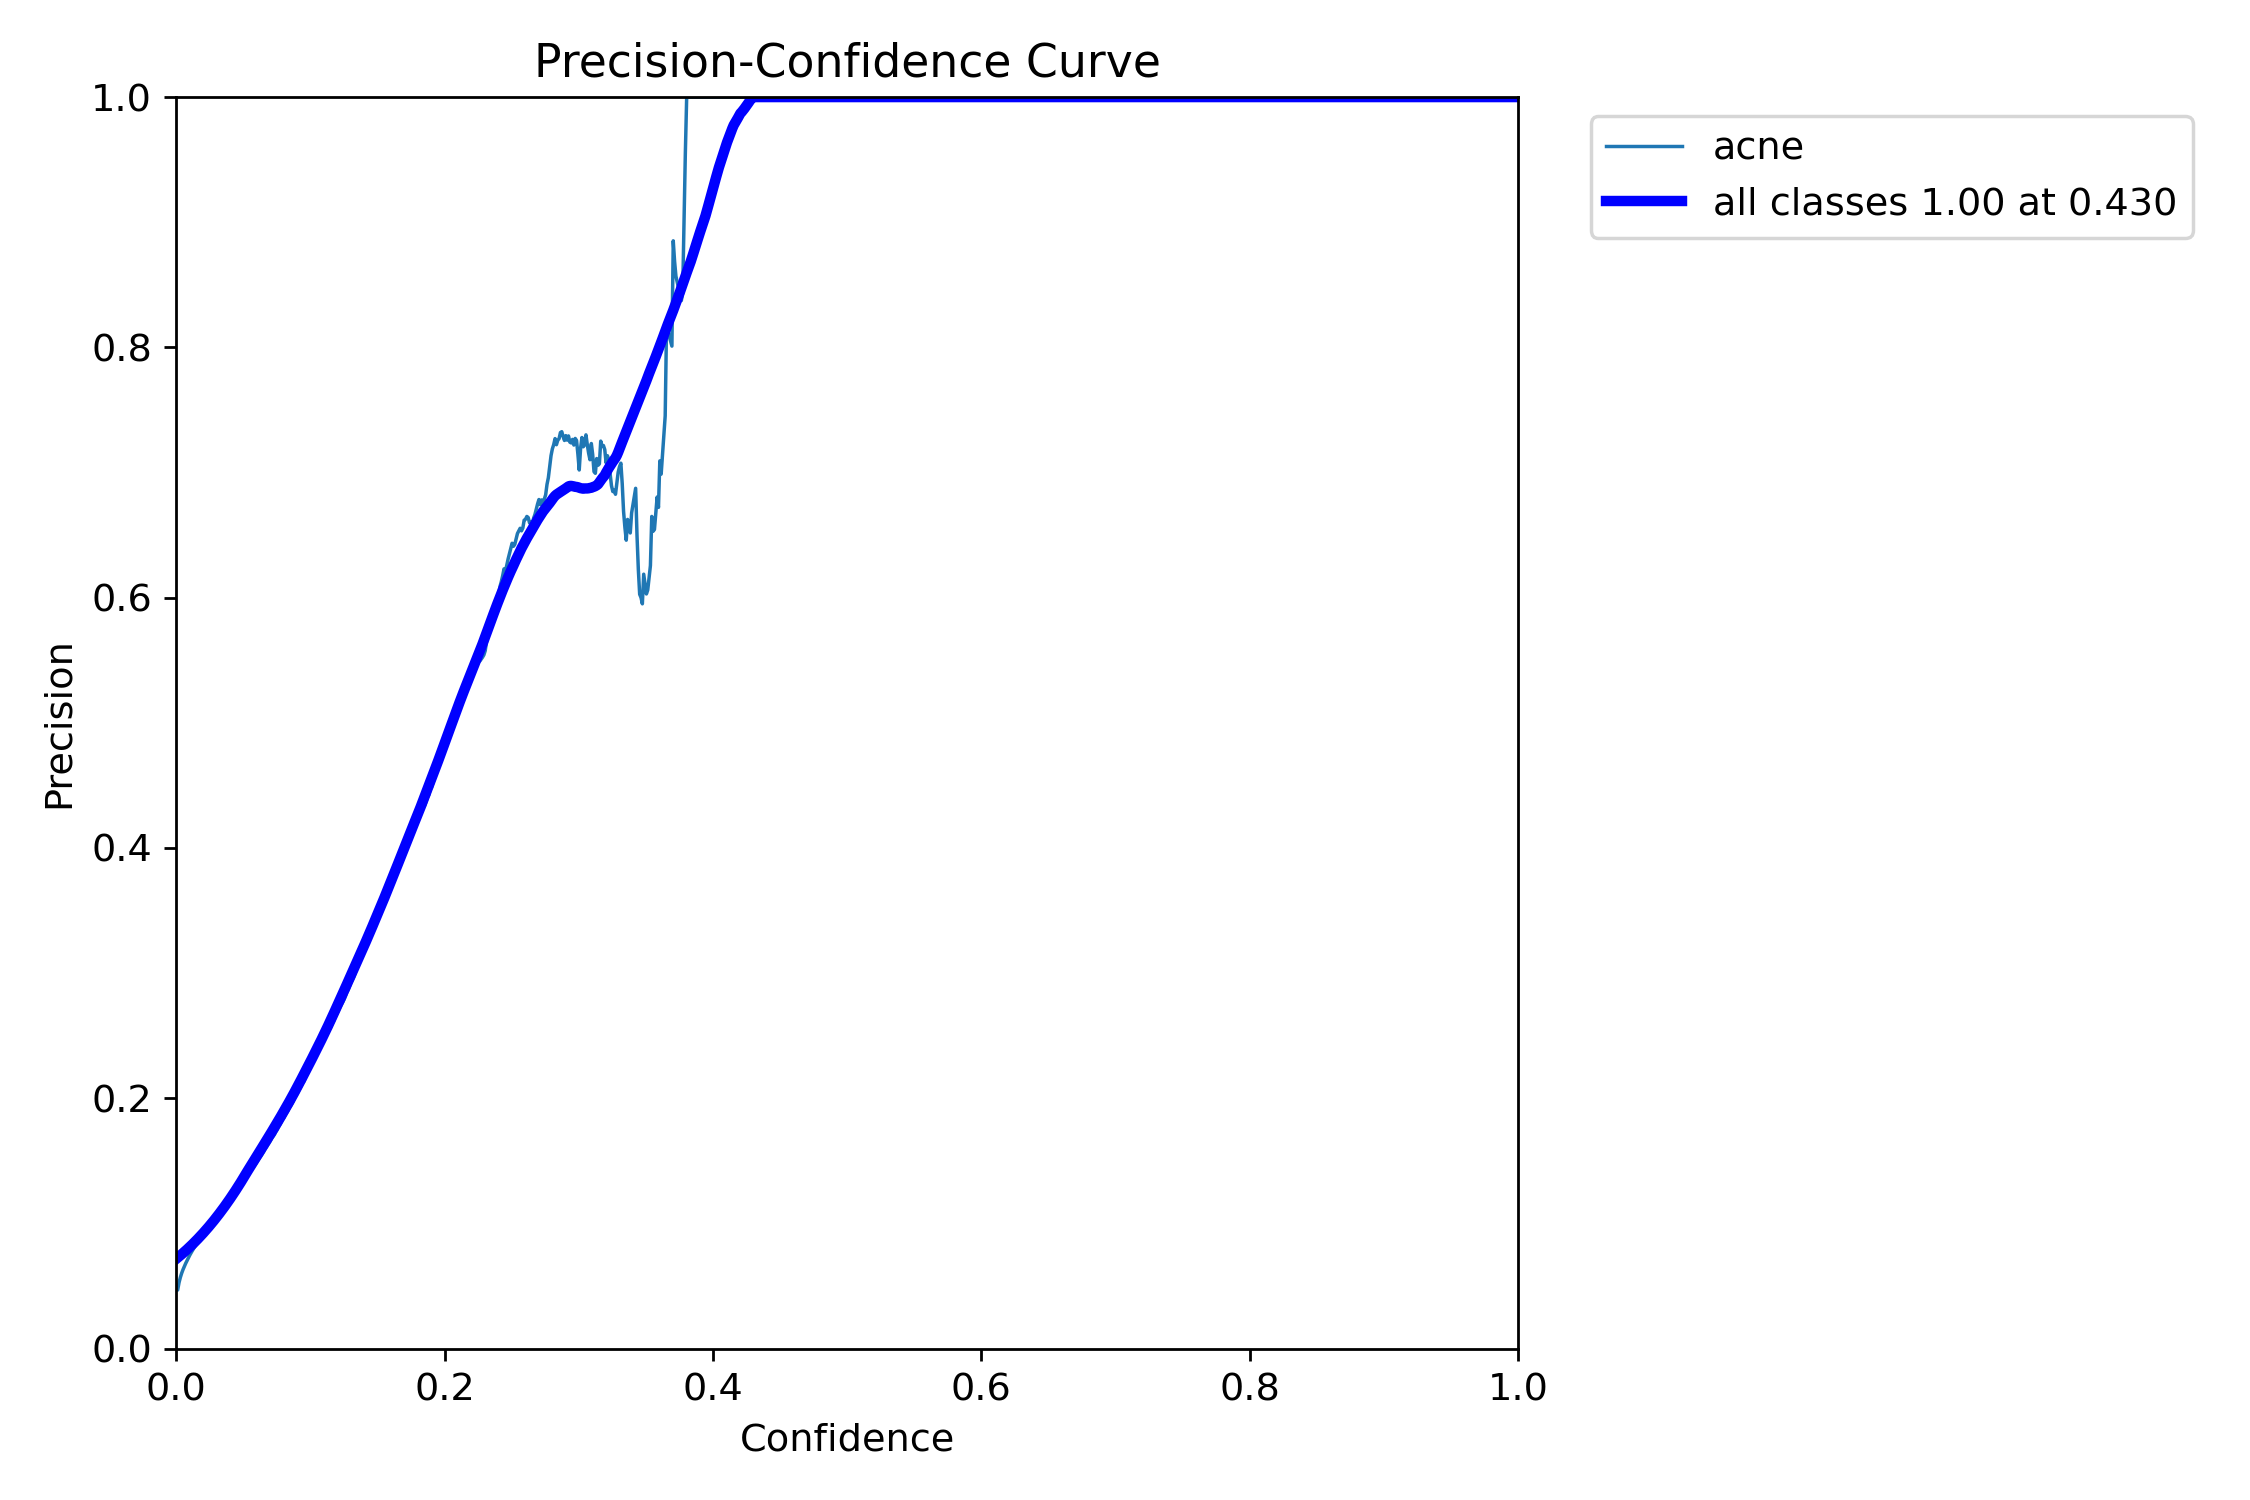

BoxR_curve.png


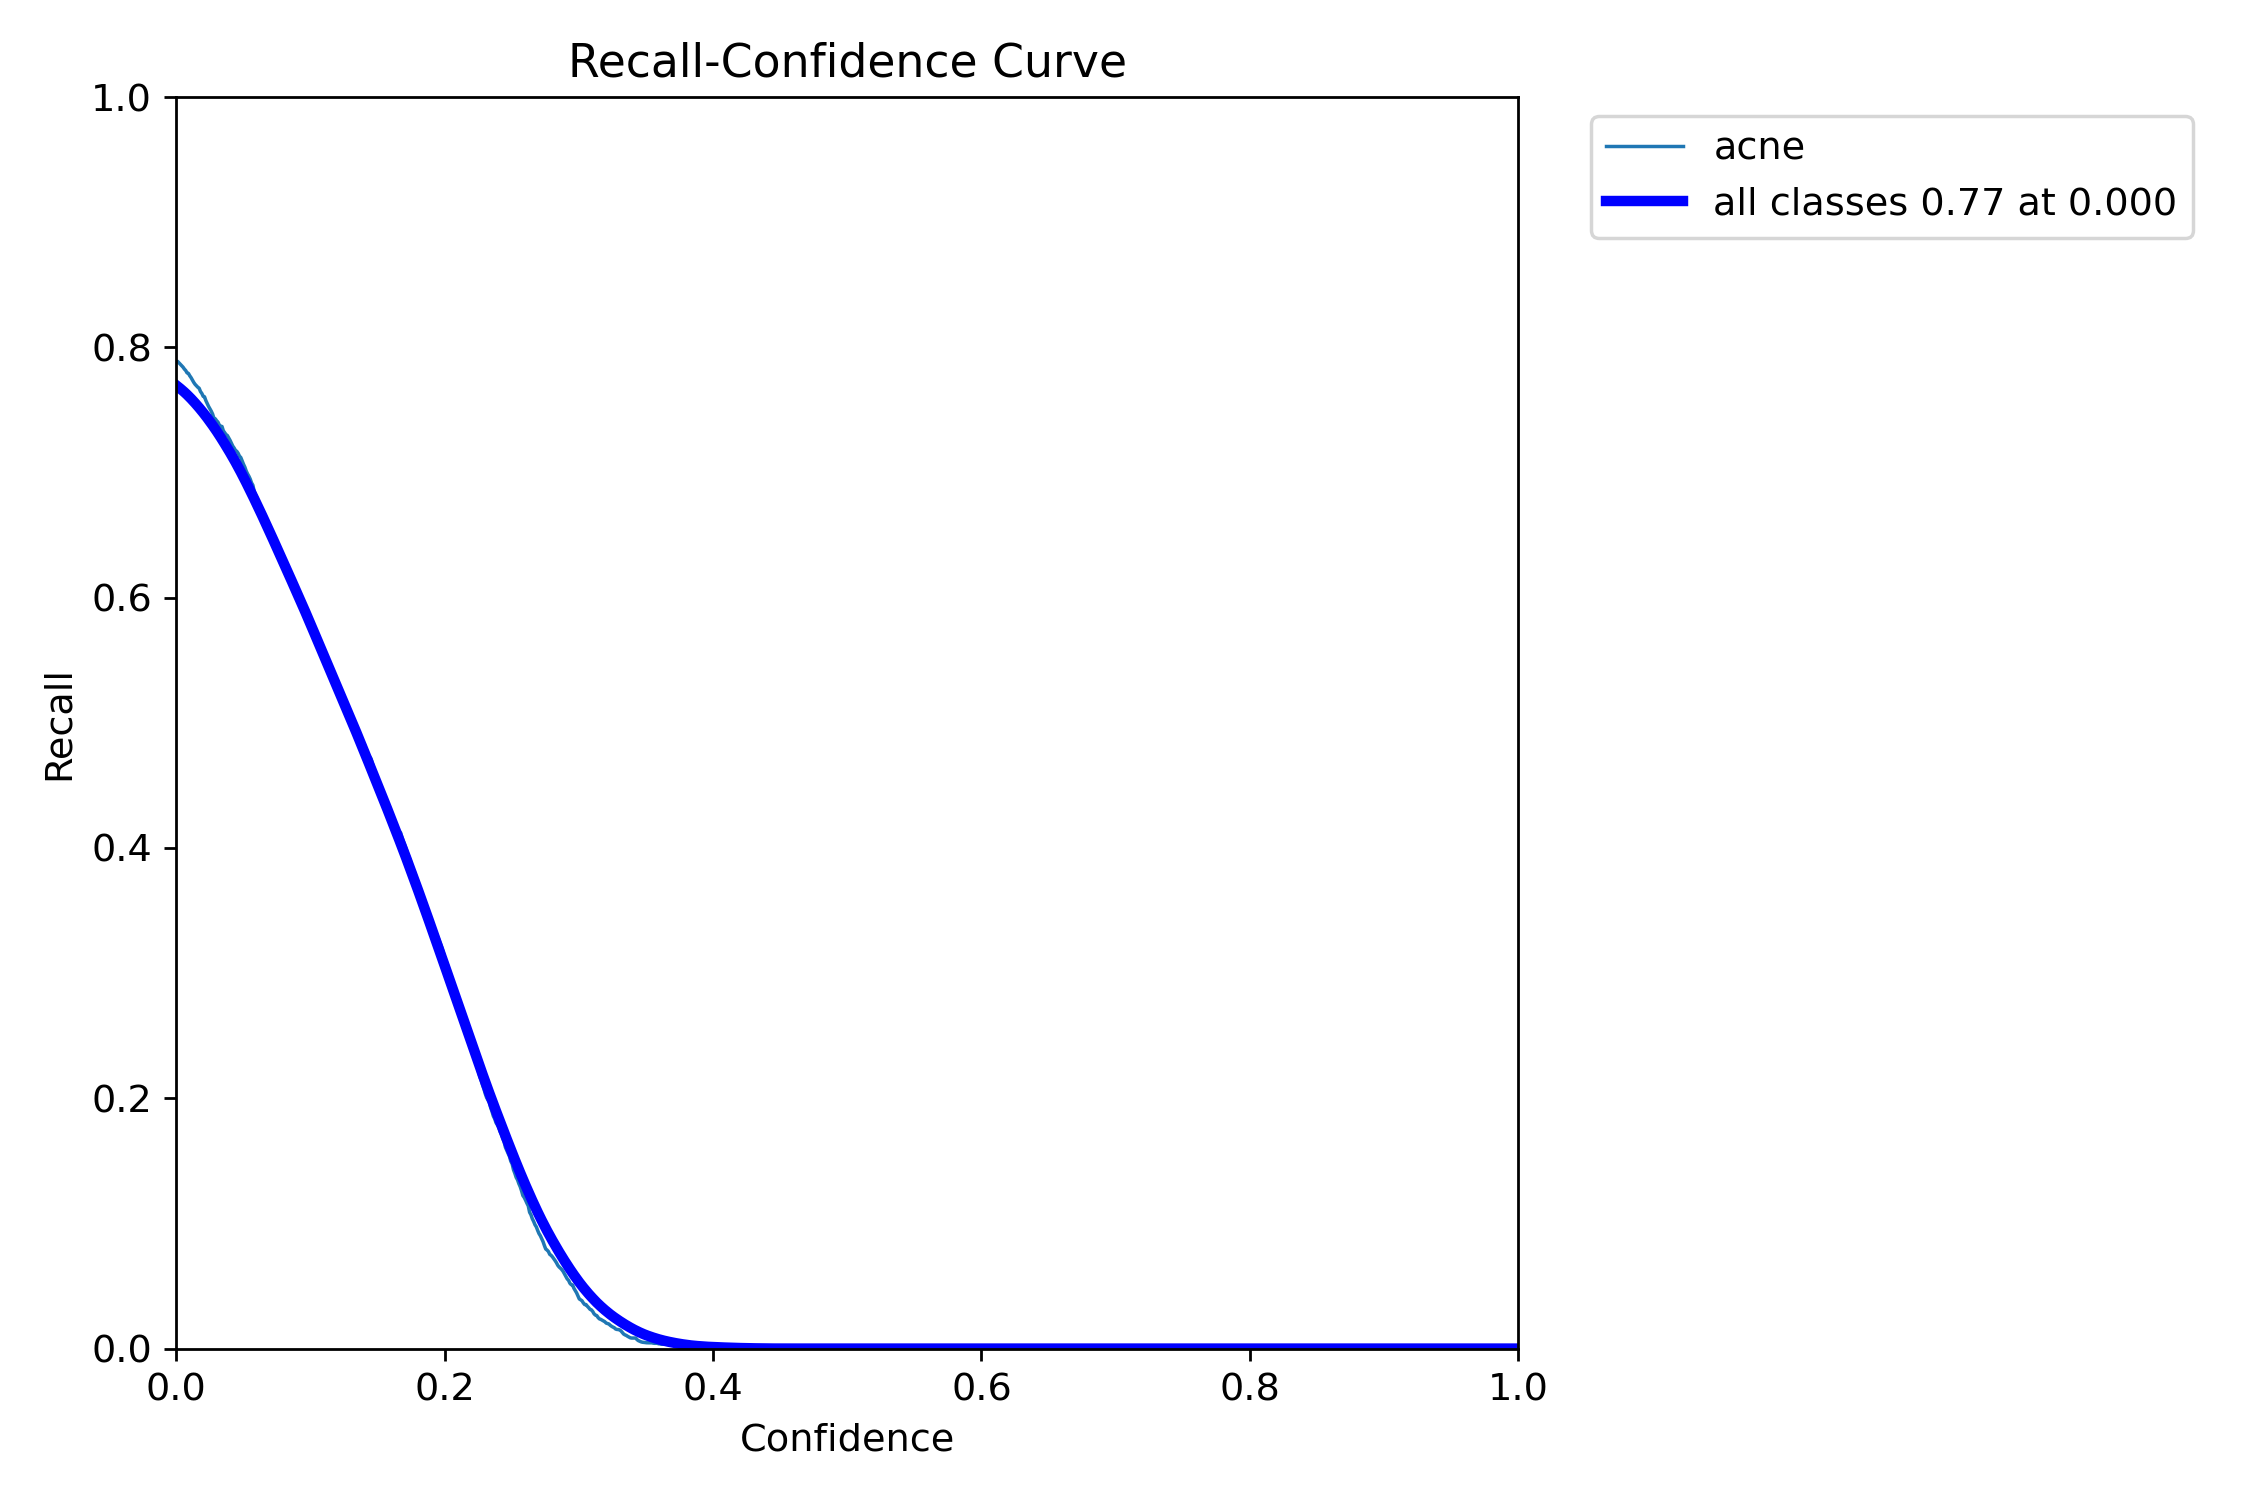

confusion_matrix.png


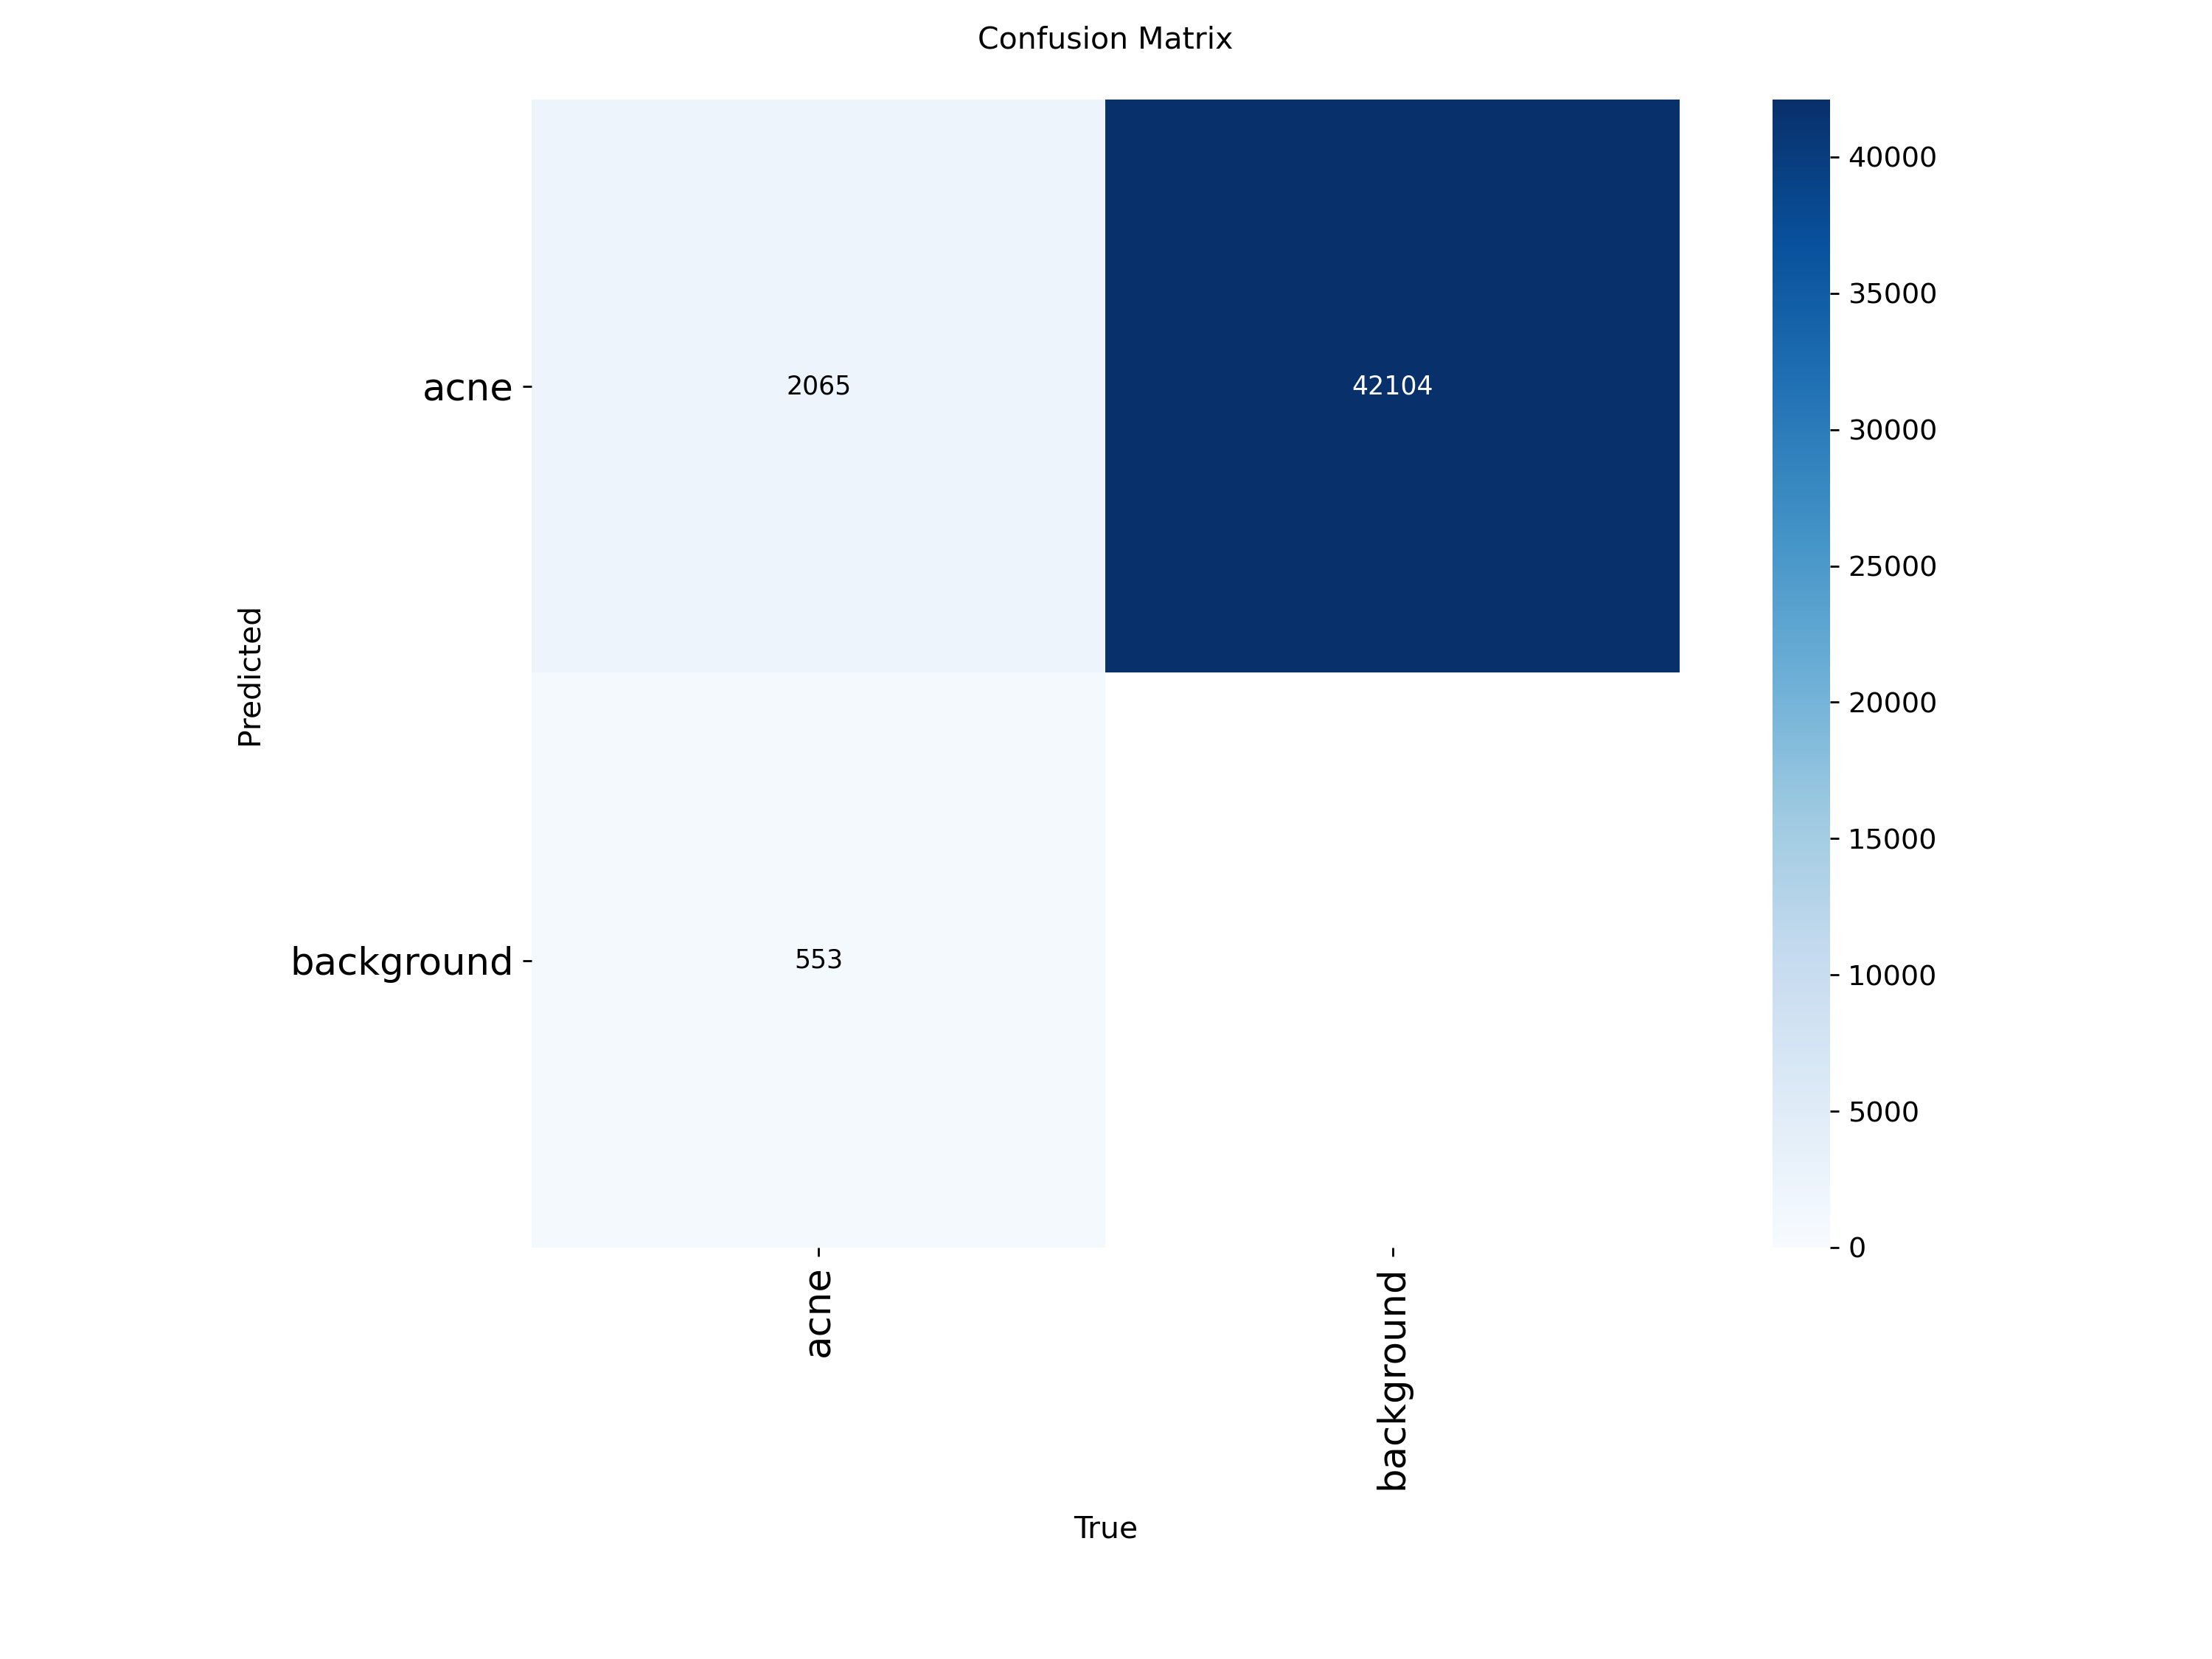

confusion_matrix_normalized.png


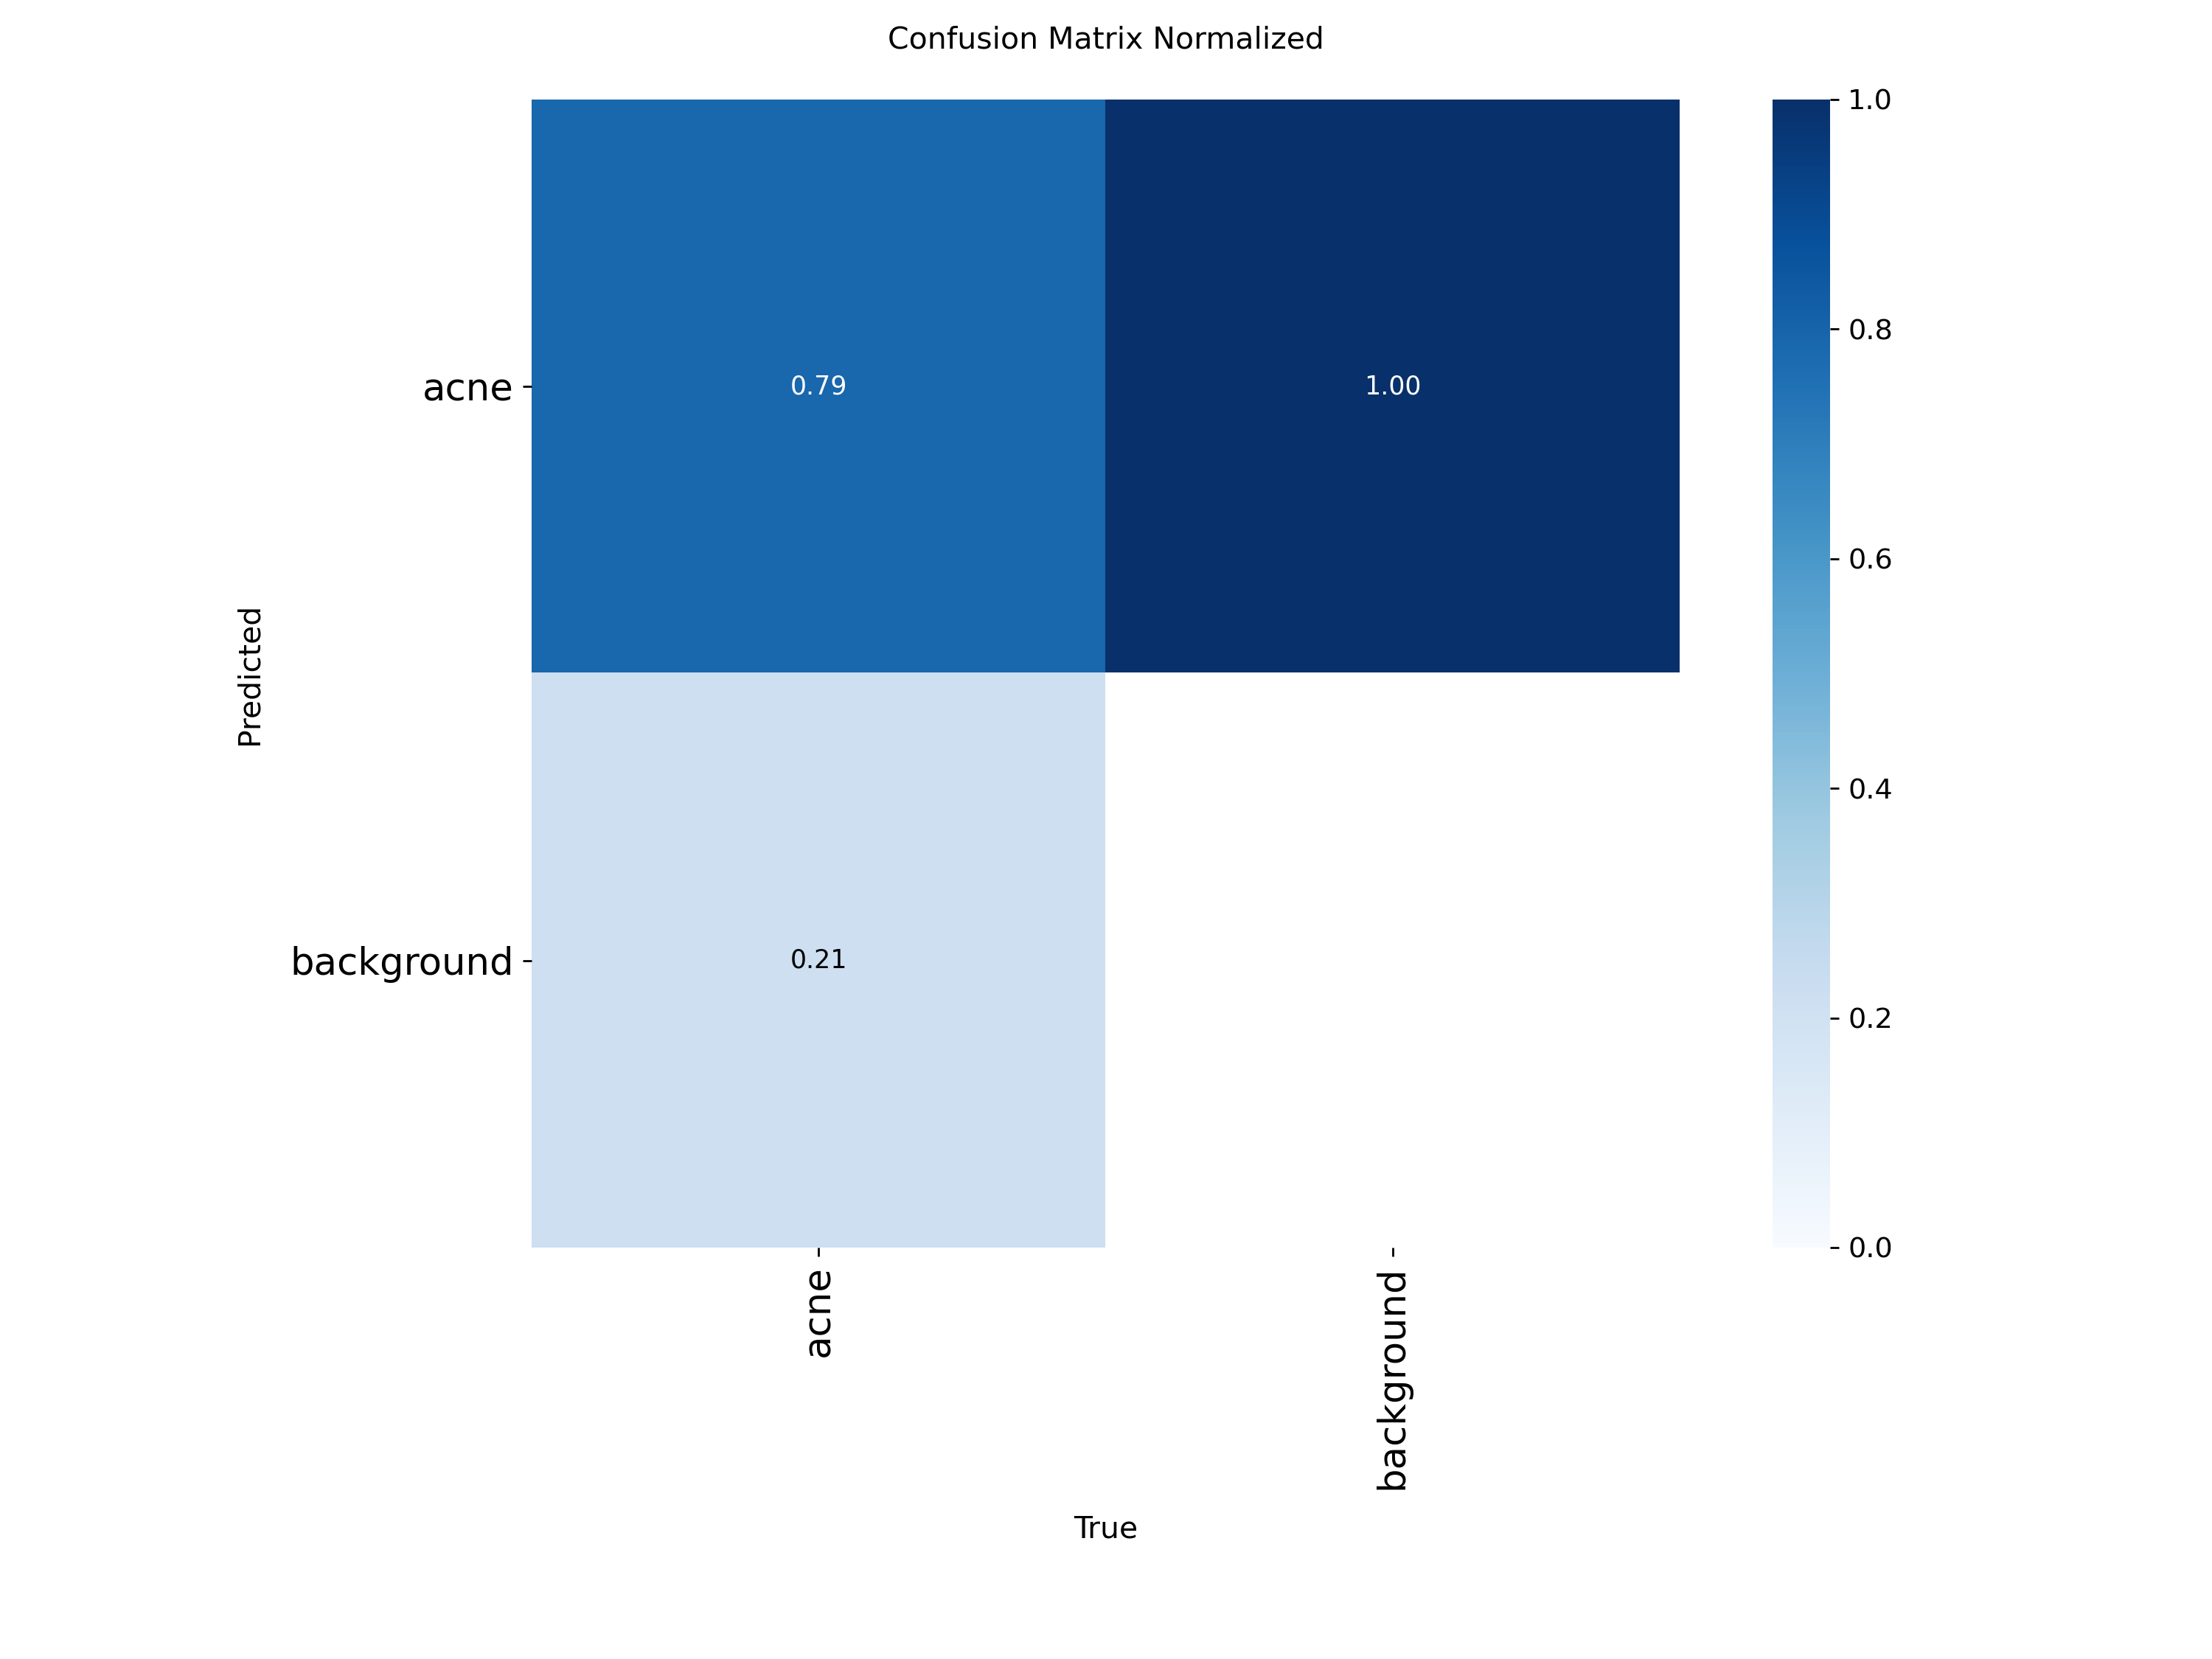

In [ ]:
from IPython.display import display, Image

PLOT_DIR = MODEL_OUTPUT_DIR / "validation_evaluation"

plot_names = [
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png"
]

for name in plot_names:
    path = PLOT_DIR / name
    print(name)
    display(Image(filename=str(path)))

In [30]:
from ultralytics import YOLO
from pathlib import Path

BEST_MODEL = (
    MODEL_OUTPUT_DIR
    / RUN_NAME
    / "weights"
    / "best.pt"
)

VAL_IMAGES = (
    DATASET_DIR
    / "images"
    / "validation"
)

ERROR_ANALYSIS_DIR = MODEL_OUTPUT_DIR / "error_analysis"

model = YOLO(str(BEST_MODEL))

results = model.predict(
    source=str(VAL_IMAGES),
    imgsz=640,
    conf=0.25,
    save=True,
    save_txt=True,
    save_conf=True,
    project=str(ERROR_ANALYSIS_DIR),
    name="validation_predictions",
    exist_ok=True
)

print("Validation predictions generated!")
print("Saved location:", ERROR_ANALYSIS_DIR / "validation_predictions")
print("Images processed:", len(results))


image 1/206 /content/gdrive/MyDrive/SkinCare_AI/ACNE04/yolo_dataset_v1/images/validation/levle0_1.jpg: 640x576 1 acne, 8.2ms
image 2/206 /content/gdrive/MyDrive/SkinCare_AI/ACNE04/yolo_dataset_v1/images/validation/levle0_10.jpg: 640x640 (no detections), 16.0ms
image 3/206 /content/gdrive/MyDrive/SkinCare_AI/ACNE04/yolo_dataset_v1/images/validation/levle0_115.jpg: 640x576 1 acne, 12.2ms
image 4/206 /content/gdrive/MyDrive/SkinCare_AI/ACNE04/yolo_dataset_v1/images/validation/levle0_121.jpg: 640x576 1 acne, 13.2ms
image 5/206 /content/gdrive/MyDrive/SkinCare_AI/ACNE04/yolo_dataset_v1/images/validation/levle0_123.jpg: 640x576 1 acne, 14.4ms
image 6/206 /content/gdrive/MyDrive/SkinCare_AI/ACNE04/yolo_dataset_v1/images/validation/levle0_140.jpg: 640x576 (no detections), 13.7ms
image 7/206 /content/gdrive/MyDrive/SkinCare_AI/ACNE04/yolo_dataset_v1/images/validation/levle0_152.jpg: 640x576 (no detections), 12.6ms
image 8/206 /content/gdrive/MyDrive/SkinCare_AI/ACNE04/yolo_dataset_v1/images/va

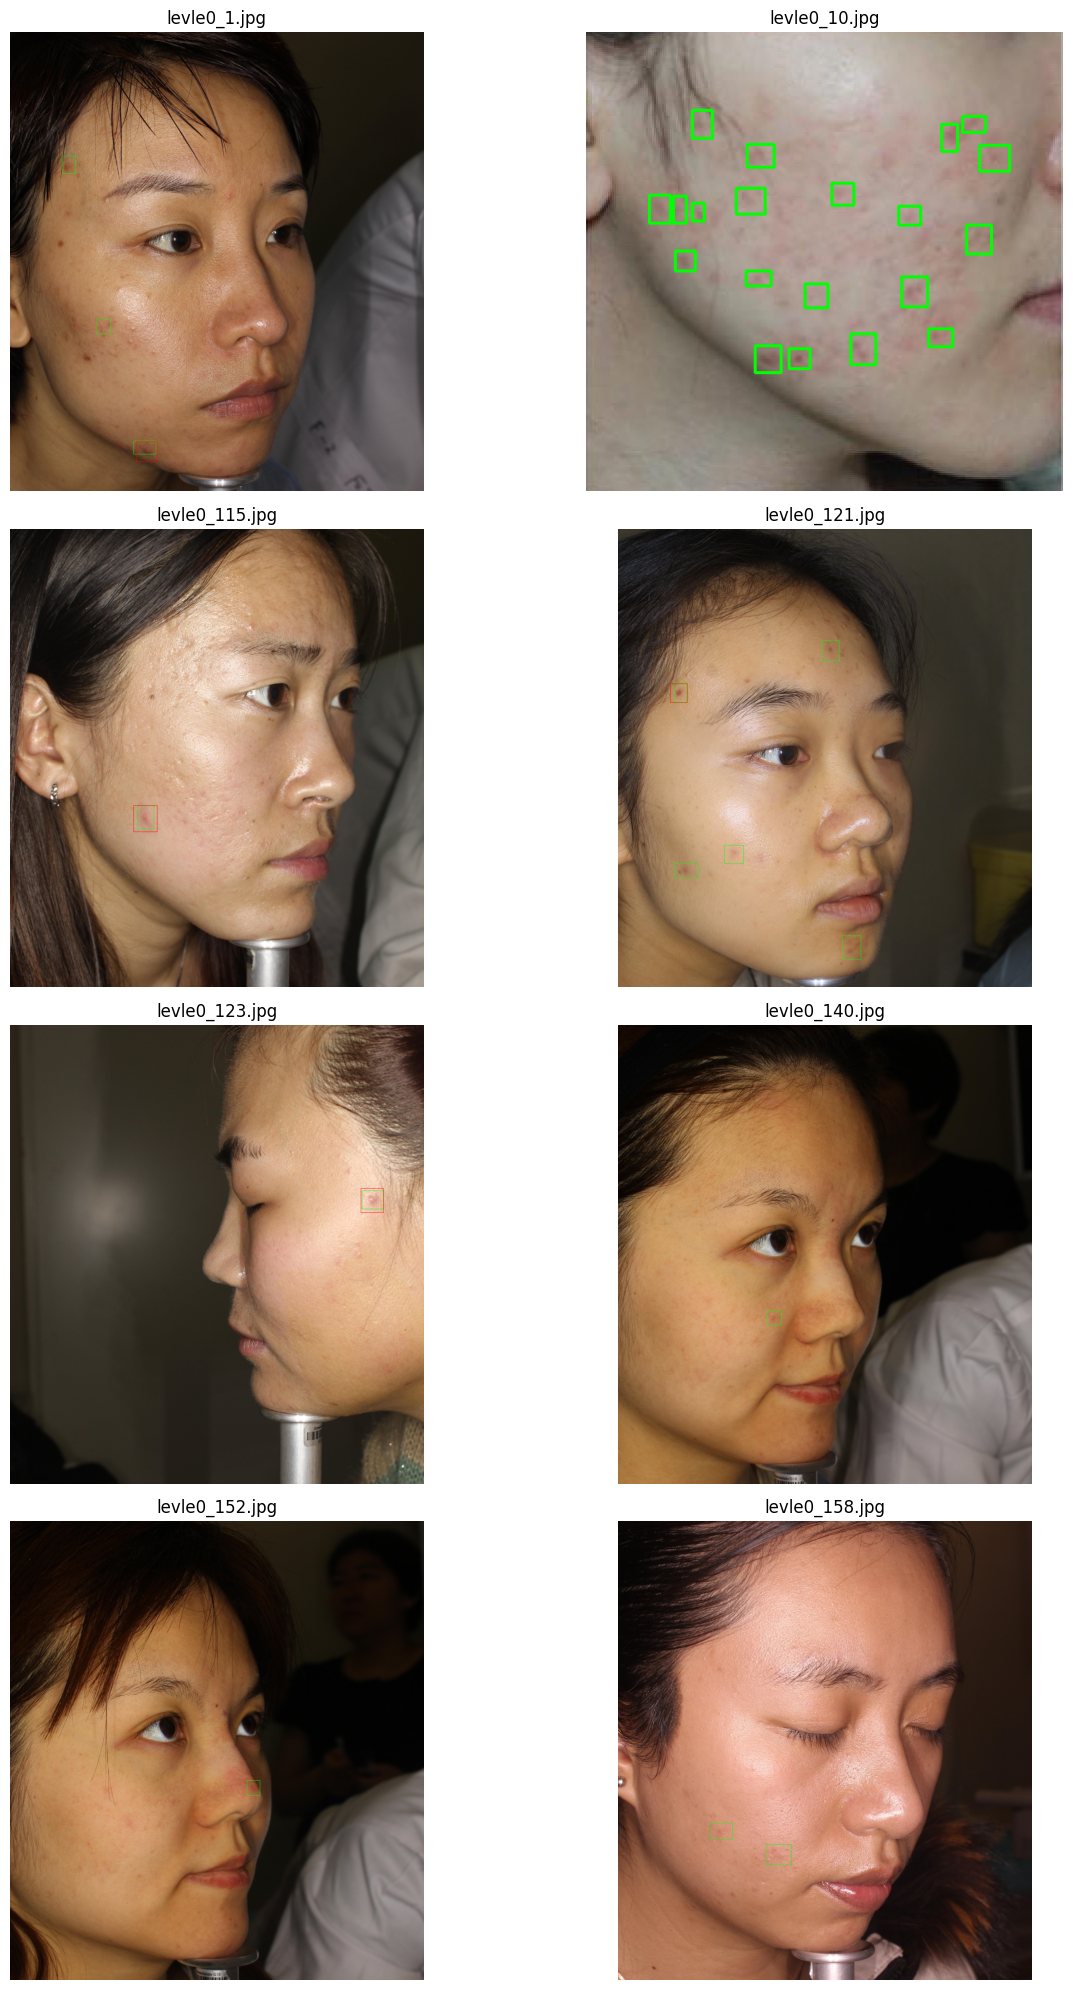

In [31]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path("/content/gdrive/MyDrive/SkinCare_AI/ACNE04")

IMAGE_DIR = BASE_DIR / "yolo_dataset_v1/images/validation"
GT_DIR = BASE_DIR / "yolo_dataset_v1/labels/validation"

PRED_DIR = (
    BASE_DIR
    / "model_outputs/error_analysis/validation_predictions/labels"
)

# Select 8 validation images
image_files = sorted(IMAGE_DIR.glob("*.jpg"))[:8]

fig, axes = plt.subplots(4, 2, figsize=(14, 20))
axes = axes.flatten()

for i, image_path in enumerate(image_files):

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width = image.shape[:2]

    gt_file = GT_DIR / f"{image_path.stem}.txt"
    pred_file = PRED_DIR / f"{image_path.stem}.txt"

    # Draw ground-truth boxes in green
    if gt_file.exists():
        for line in gt_file.read_text().splitlines():
            values = list(map(float, line.split()[:5]))
            _, x, y, w, h = values

            x1 = int((x - w / 2) * width)
            y1 = int((y - h / 2) * height)
            x2 = int((x + w / 2) * width)
            y2 = int((y + h / 2) * height)

            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

    # Draw predicted boxes in red
    if pred_file.exists():
        for line in pred_file.read_text().splitlines():
            values = list(map(float, line.split()[:5]))
            _, x, y, w, h = values

            x1 = int((x - w / 2) * width)
            y1 = int((y - h / 2) * height)
            x2 = int((x + w / 2) * width)
            y2 = int((y + h / 2) * height)

            cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)

    axes[i].imshow(image)
    axes[i].set_title(image_path.name)
    axes[i].axis("off")

plt.tight_layout()
plt.show()